# Учебное исследование территории Выборга с BlocksNet

**Что это за ноутбук.** Пошаговый учебный пример: загружаем открытые данные OpenStreetMap,
нарезаем территорию на кварталы, считаем время передвижения между кварталами и повторяем
показатели из `examples/pipeline.ipynb` библиотеки BlocksNet.

**Что получится.** Папка `examples/data/vyborg/` с GeoJSON-слоями, таблицами, графиками и
итоговым файлом `blocks_results.geojson`. Эти же файлы потом можно использовать для отдельной
HTML-страницы с интерактивной картой и дашбордом.

**Главное правило.** Ноутбук специально остановится после подготовки кварталов. Расчёты
включены только после того, как мы согласуем список метрик. Не запускайте `Run All` сразу:
лучше идти по ячейкам сверху вниз.

**Источники данных.**
- OpenStreetMap, © участники OpenStreetMap, лицензия ODbL: https://www.openstreetmap.org/
- Граница Выборга: OSM relation 1572051.
- Пешеходный граф: OpenStreetMap / Overpass API, скорость 5 км/ч.
- BlocksNet 1.0.0a9: https://github.com/aimclub/blocksnet

## 0. Как запускать

1. Установите зависимости один раз (команды есть в конце ноутбука).
2. Откройте этот ноутбук в Jupyter Lab или Jupyter Notebook.
3. Выберите ядро `.venv`.
4. Запускайте ячейки по порядку до большого блока **STOP**.
5. Посмотрите карту кварталов, напишите мне и согласуйте метрики.
6. После согласования поменяйте `RUN_CALCULATIONS = True` в ячейке с константами
   и запустите расчётные ячейки.

Если файлы уже есть, при `USE_CACHE = True` ноутбук прочитает их с диска и не будет
скачивать заново. Для принудительного обновления поставьте `USE_CACHE = False`.

In [1]:
import importlib.metadata as md
import json
import pickle
import sys
import warnings
from pathlib import Path

import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import osmnx as ox
import pandas as pd
from IPython.display import display

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 180)
plt.rcParams["figure.figsize"] = (10, 8)

print("Python:", sys.version.split()[0])
for package in ["blocksnet", "geopandas", "osmnx", "pandas", "numpy", "shapely", "iduedu"]:
    try:
        print(f"{package}: {md.version(package)}")
    except md.PackageNotFoundError:
        print(f"{package}: НЕ УСТАНОВЛЕН")


Python: 3.12.10
blocksnet: 1.0.0a9
geopandas: 1.2.0
osmnx: 2.1.1
pandas: 2.3.3
numpy: 2.2.6
shapely: 2.2.0
iduedu: 0.4.1


In [2]:
def find_project_root(start: Path) -> Path:
    """Ищет папку, в которой лежит pyproject.toml."""
    for candidate in [start, *start.parents]:
        if (candidate / "pyproject.toml").exists():
            return candidate
    return start


PROJECT_ROOT = find_project_root(Path.cwd())
DATA_DIR = PROJECT_ROOT / "examples" / "data" / "vyborg"
RAW_DIR = DATA_DIR / "raw"
PROCESSED_DIR = DATA_DIR / "processed"
CACHE_DIR = DATA_DIR / "cache"
RESULTS_DIR = DATA_DIR / "results"

for folder in (RAW_DIR, PROCESSED_DIR, CACHE_DIR, RESULTS_DIR):
    folder.mkdir(parents=True, exist_ok=True)

# --- Параметры исследования ---
TERRITORY_LABEL = "Выборг"
TERRITORY_OSM_ID = 1572051          # OSM relation «город Выборг»
GRAPH_TYPE = "walk"                 # пешеходный граф; intermodal не используем
WALK_SPEED_KMH = 5.0                # средняя скорость пешехода
USE_CACHE = True                    # читать готовые файлы, если они есть
RUN_CALCULATIONS = True            # СТОП: включим после согласования метрик

# --- Параметры импутации (как в pipeline) ---
DEFAULT_NUMBER_OF_FLOORS = 1
LIVING_DEMAND_M2_PER_PERSON = 30
SCHOOL_SERVICE_TYPE = "school"

# --- Настройки OSMnx ---
ox.settings.use_cache = True
ox.settings.cache_folder = str(CACHE_DIR / "osmnx")
(CACHE_DIR / "osmnx").mkdir(parents=True, exist_ok=True)

print("Корень проекта:", PROJECT_ROOT)
print("Папка данных:", DATA_DIR)
print("Граф:", GRAPH_TYPE, f"{WALK_SPEED_KMH} км/ч")
print("Расчёты включены:", RUN_CALCULATIONS)


Корень проекта: D:\ai\python-package-boilerplate-main\python-package-boilerplate-main
Папка данных: D:\ai\python-package-boilerplate-main\python-package-boilerplate-main\examples\data\vyborg
Граф: walk 5.0 км/ч
Расчёты включены: True


In [3]:
def _stringify(value):
    """Приводит значения OSM/Enum к простому виду, который можно сохранить в GeoJSON."""
    if value is None:
        return None
    if hasattr(value, "value") and not isinstance(value, (str, bytes)):
        return str(value.value)
    if isinstance(value, (list, tuple)):
        return ", ".join(str(item) for item in value)
    if isinstance(value, dict):
        return json.dumps(value, ensure_ascii=False)
    try:
        if pd.isna(value):
            return None
    except (TypeError, ValueError):
        pass
    return value


def read_geojson(path: Path) -> gpd.GeoDataFrame:
    path = Path(path)
    if not path.exists():
        raise FileNotFoundError(
            f"Нет файла {path}. Сначала запустите ячейку, которая его создаёт."
        )
    gdf = gpd.read_file(path)
    if gdf.crs is None:
        raise ValueError(f"В файле {path} не указана система координат.")
    return gdf


def write_geojson(gdf: gpd.GeoDataFrame, path: Path) -> None:
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    out = gdf.copy()
    if out.crs is None:
        raise ValueError("Нельзя сохранить GeoJSON без системы координат.")
    # GeoJSON не хранит индекс. Если у таблицы есть block_id, сохраняем его колонкой.
    if out.index.name is not None:
        out = out.reset_index()
    for column in out.columns:
        if column == out.geometry.name:
            continue
        if out[column].dtype == object:
            out[column] = out[column].map(_stringify)
    numeric_columns = out.select_dtypes(include=[np.number]).columns
    if len(numeric_columns) > 0:
        out[numeric_columns] = out[numeric_columns].replace([np.inf, -np.inf], np.nan)
    out.to_crs(4326).to_file(path, driver="GeoJSON")
    print(f"Сохранено: {path}")


def load_boundary_and_crs():
    """Читает границу и возвращает её в WGS84 и в метрической проекции."""
    boundary = read_geojson(RAW_DIR / "boundary.geojson").to_crs(4326)
    metric = boundary.estimate_utm_crs()
    return boundary, boundary.to_crs(metric), metric


def ensure_block_index(gdf: gpd.GeoDataFrame) -> gpd.GeoDataFrame:
    """Делает block_id индексом, чтобы таблицы соединялись без путаницы."""
    if "block_id" in gdf.columns:
        gdf = gdf.set_index("block_id")
    if gdf.index.name != "block_id":
        gdf.index.name = "block_id"
    gdf.index = gdf.index.astype(int)
    return gdf


def join_extra(base: pd.DataFrame, extra: pd.DataFrame) -> pd.DataFrame:
    """Присоединяет таблицу, не создавая одинаковых колонок."""
    extra = extra.copy()
    duplicates = [column for column in extra.columns if column in base.columns]
    extra = extra.drop(columns=duplicates)
    return base.join(extra, how="left")


print("Вспомогательные функции готовы.")


Вспомогательные функции готовы.


## 1. Граница территории

Скачиваем границу города Выборга по OSM ID. Это не весь Выборгский район, а городское
поселение / город. Если граница выглядит неправильно, проверьте `TERRITORY_OSM_ID` в ячейке
с константами. Если вы поменяли `TERRITORY_OSM_ID`, сначала удалите папки
`examples/data/vyborg/raw` и `examples/data/vyborg/cache`: иначе ноутбук возьмёт старую
границу, старые слои OSM и старый граф.

Граница сохраняется в `raw/boundary.geojson`. Все расчёты потом идут в метрической
проекции UTM, а GeoJSON — в обычных градусах WGS84.

Граница уже есть, читаем с диска.
Объектов границы: 1
Метрическая система координат: EPSG:32635
Площадь границы, км²: 160.79


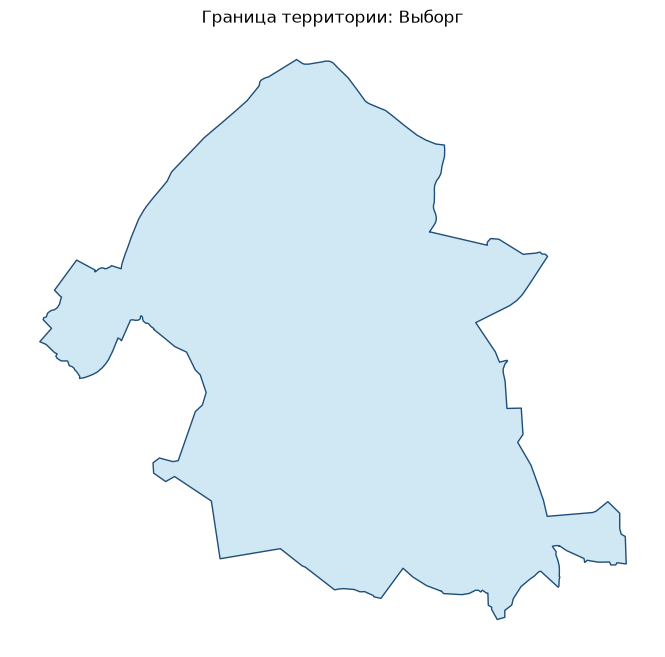

In [4]:
boundary_path = RAW_DIR / "boundary.geojson"

if USE_CACHE and boundary_path.exists():
    print("Граница уже есть, читаем с диска.")
else:
    try:
        boundaries = ox.geocode_to_gdf(f"R{TERRITORY_OSM_ID}", by_osmid=True)
    except Exception as error:
        print("Не удалось загрузить границу по OSM ID:", error)
        print("Пробуем загрузить по названию.")
        boundaries = ox.geocode_to_gdf("Vyborg, Leningrad Oblast, Russia")
    boundaries = boundaries[["geometry"]].copy()
    write_geojson(boundaries, boundary_path)

boundaries, boundaries_metric, metric_crs = load_boundary_and_crs()

print("Объектов границы:", len(boundaries))
print("Метрическая система координат:", metric_crs)
print("Площадь границы, км²:", round(boundaries_metric.area.sum() / 1_000_000, 2))

fig, ax = plt.subplots(figsize=(10, 8))
boundaries_metric.plot(ax=ax, color="#cfe8f3", edgecolor="#1f4e79", linewidth=1)
ax.set_title(f"Граница территории: {TERRITORY_LABEL}")
ax.set_axis_off()
plt.show()


## 2. Дороги, железные дороги и вода

Загружаем объекты OpenStreetMap по тегам из `pipeline.ipynb`, оставляем только линии и
полигоны и сохраняем в отдельные GeoJSON. Это исходные слои для нарезки кварталов.

Если Overpass API отвечает медленно, подождите и перезапустите ячейку. Уже сохранённые
слои при `USE_CACHE = True` повторно не скачиваются.

roads: загружено из кэша, объектов 2299
railways: загружено из кэша, объектов 283
water: загружено из кэша, объектов 1326


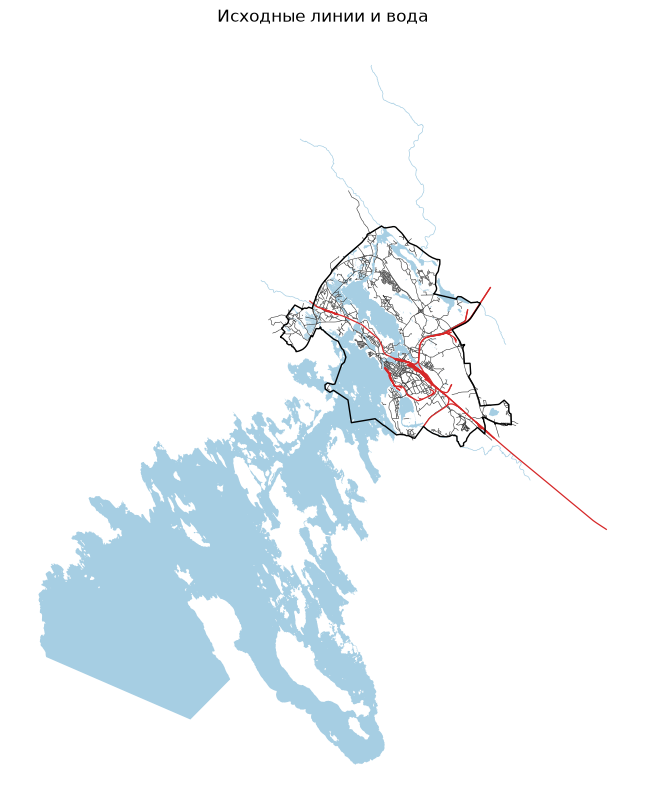

In [5]:
# Теги как в examples/pipeline.ipynb
bc_tags = {
    "roads": {
        "highway": [
            "construction", "crossing", "living_street", "motorway", "motorway_link",
            "motorway_junction", "pedestrian", "primary", "primary_link", "raceway",
            "residential", "road", "secondary", "secondary_link", "services", "tertiary",
            "tertiary_link", "track", "trunk", "trunk_link", "turning_circle",
            "turning_loop", "unclassified",
        ],
        "service": ["living_street", "emergency_access"],
    },
    "railways": {"railway": "rail"},
    "water": {
        "riverbank": True,
        "reservoir": True,
        "basin": True,
        "dock": True,
        "canal": True,
        "pond": True,
        "natural": ["water", "bay"],
        "waterway": ["river", "canal", "ditch"],
        "landuse": "basin",
        "water": "lake",
    },
}


def load_osm_layer(name, tags, allowed_types):
    path = RAW_DIR / f"{name}.geojson"
    if USE_CACHE and path.exists():
        layer = read_geojson(path)
        print(f"{name}: загружено из кэша, объектов {len(layer)}")
    else:
        layer = ox.features_from_polygon(
            boundaries.to_crs(4326).union_all(),
            tags=tags,
        )
        layer = layer[layer.geom_type.isin(allowed_types)].copy()
        layer = layer[["geometry"]].reset_index(drop=True)
        write_geojson(layer, path)
        print(f"{name}: скачано из OSM, объектов {len(layer)}")
    if len(layer) == 0:
        raise ValueError(f"Слой {name} пустой. Проверьте территорию и теги OSM.")
    return layer.to_crs(metric_crs)


roads = load_osm_layer("roads", bc_tags["roads"], ["LineString", "MultiLineString"])
railways = load_osm_layer("railways", bc_tags["railways"], ["LineString", "MultiLineString"])
water = load_osm_layer(
    "water",
    bc_tags["water"],
    ["Polygon", "MultiPolygon", "LineString", "MultiLineString"],
)

fig, ax = plt.subplots(figsize=(12, 10))
water.plot(ax=ax, color="#a6cee3", linewidth=0.5)
roads.plot(ax=ax, color="#333333", linewidth=0.4)
railways.plot(ax=ax, color="#d62728", linewidth=0.9)
boundaries_metric.boundary.plot(ax=ax, color="black", linewidth=1)
ax.set_title("Исходные линии и вода")
ax.set_axis_off()
plt.show()


## 3. Нарезка кварталов

`preprocess_urban_objects` приводит линии и полигоны к нужному виду, а `cut_urban_blocks`
делит территорию на кварталы. Каждому кварталу присваивается устойчивый `block_id`.

Это последняя содержательная ячейка перед остановкой. После неё смотрим карту и согласуем
метрики.

2026-10-30 00:10:47.839 | INFO     | blocksnet.blocks.cutting.preprocessing.core:preprocess_urban_objects:44 - Checking roads schema
2026-10-30 00:10:47.858 | INFO     | blocksnet.blocks.cutting.preprocessing.core:preprocess_urban_objects:51 - Checking railways schema
2026-10-30 00:10:47.871 | INFO     | blocksnet.blocks.cutting.preprocessing.core:preprocess_urban_objects:58 - Checking water schema
2026-10-30 00:10:47.892 | INFO     | blocksnet.blocks.cutting.processing.schemas:validate_and_preprocess_gdfs:51 - Checking boundaries schema
2026-10-30 00:10:47.892 | INFO     | blocksnet.blocks.cutting.processing.schemas:validate_and_preprocess_gdfs:55 - Checking line objects schema
2026-10-30 00:10:47.923 | INFO     | blocksnet.blocks.cutting.processing.schemas:validate_and_preprocess_gdfs:62 - Checking polygon objects schema
2026-10-30 00:10:47.939 | INFO     | blocksnet.blocks.cutting.processing.schemas:validate_and_preprocess_gdfs:69 - Checking buildings schema
2026-10-30 00:10:47.939 

Сохранено: D:\ai\python-package-boilerplate-main\python-package-boilerplate-main\examples\data\vyborg\processed\blocks_cut.geojson
Кварталов: 1143
Суммарная площадь кварталов, км²: 123.01
Медианная площадь квартала, га: 0.45


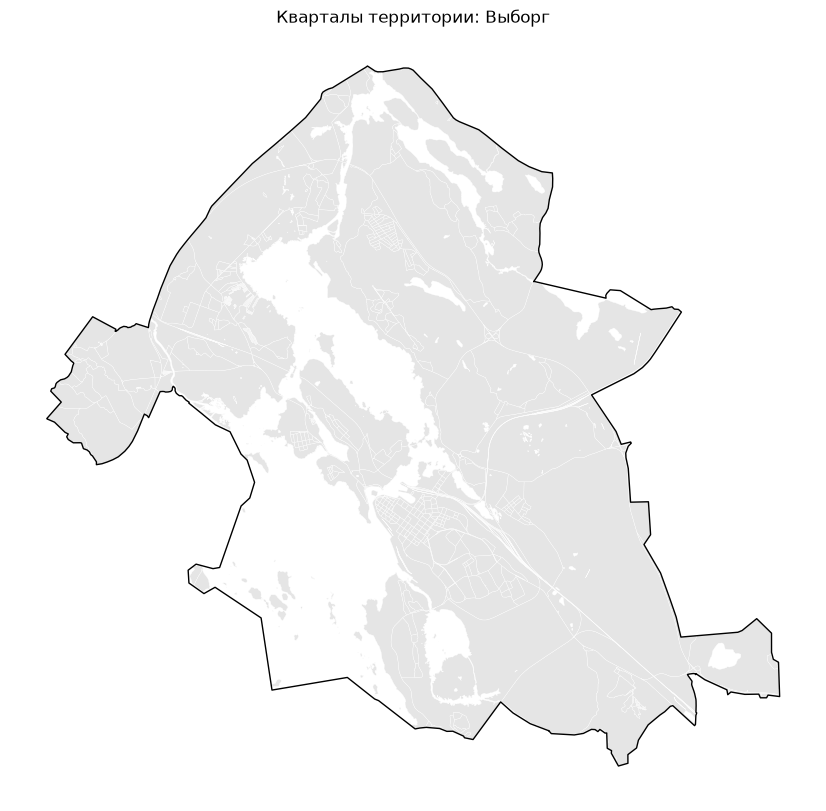

In [6]:
from blocksnet.blocks.cutting import preprocess_urban_objects, cut_urban_blocks

boundaries, boundaries_metric, metric_crs = load_boundary_and_crs()
roads = read_geojson(RAW_DIR / "roads.geojson").to_crs(metric_crs)
railways = read_geojson(RAW_DIR / "railways.geojson").to_crs(metric_crs)
water = read_geojson(RAW_DIR / "water.geojson").to_crs(metric_crs)

lines, polygons = preprocess_urban_objects(roads, railways, water)
blocks = cut_urban_blocks(boundaries_metric, lines, polygons)

blocks = blocks.reset_index(drop=True)
blocks["block_id"] = np.arange(1, len(blocks) + 1)
blocks = blocks.set_index("block_id")
blocks["site_area"] = blocks.area.astype(float)

if len(blocks) == 0:
    raise ValueError("Кварталы не получились. Проверьте исходные слои и границу.")

write_geojson(blocks, PROCESSED_DIR / "blocks_cut.geojson")

print("Кварталов:", len(blocks))
print("Суммарная площадь кварталов, км²:", round(blocks["site_area"].sum() / 1_000_000, 2))
print("Медианная площадь квартала, га:", round(blocks["site_area"].median() / 10_000, 2))

fig, ax = plt.subplots(figsize=(12, 10))
blocks.plot(ax=ax, color="#e5e5e5", edgecolor="white", linewidth=0.25)
boundaries_metric.boundary.plot(ax=ax, color="black", linewidth=1)
ax.set_title(f"Кварталы территории: {TERRITORY_LABEL}")
ax.set_axis_off()
plt.show()


## 4. Функциональное использование территории (land use)

Загружаем `landuse` из OSM и назначаем кварталам преобладающее использование по правилам
из `pipeline.ipynb`. Значение `land_use` потом пригодится для карты и выводов.

Кварталы без данных получат `no_data` — это нормально для неполных данных OSM.

Функциональные зоны загружены из кэша.


2026-10-30 00:10:50.410 | WARNING  | blocksnet.blocks.assignment.land_use:_preprocess_functional_zones:17 - Functional zones not in rules: railway, greenhouse_horticulture, logging, plant_nursery, orchard, allotments, farmyard, quarry, meadow, reservoir


Сохранено: D:\ai\python-package-boilerplate-main\python-package-boilerplate-main\examples\data\vyborg\processed\blocks.geojson
Кварталов с land use: 337 из 1143


,кварталов
land_use,
no_data,806
residential,192
recreation,63
industrial,44
business,17
special,12
agriculture,8
transport,1


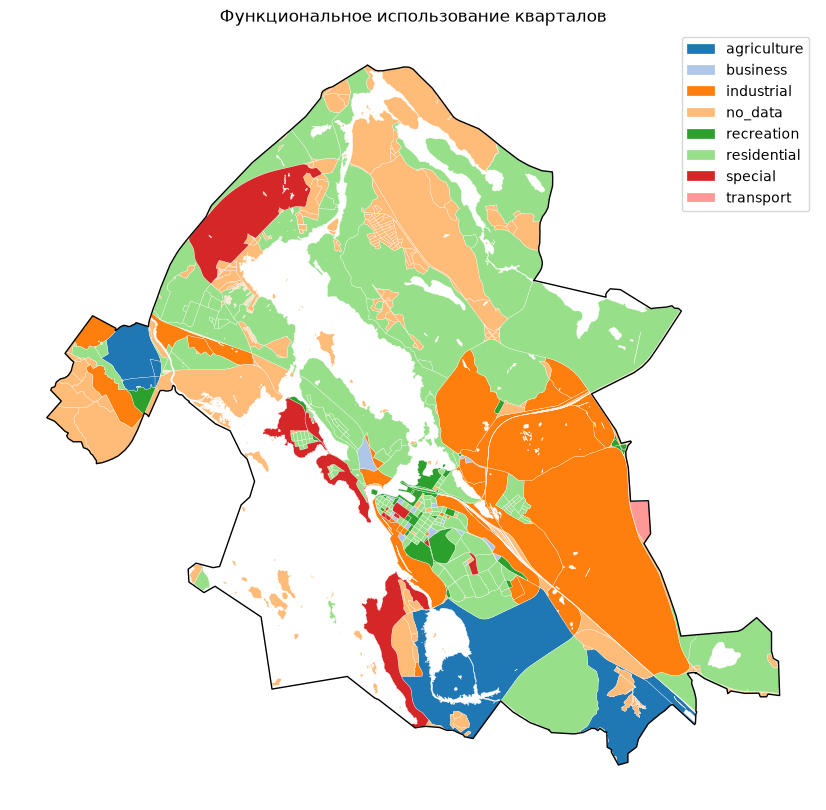

In [7]:
from blocksnet.blocks.assignment import assign_land_use
from blocksnet.enums import LandUse

boundaries, boundaries_metric, metric_crs = load_boundary_and_crs()
blocks = ensure_block_index(read_geojson(PROCESSED_DIR / "blocks_cut.geojson")).to_crs(metric_crs)

functional_zones_path = RAW_DIR / "functional_zones.geojson"
if USE_CACHE and functional_zones_path.exists():
    functional_zones = read_geojson(functional_zones_path)
    print("Функциональные зоны загружены из кэша.")
else:
    functional_zones = ox.features_from_polygon(
        boundaries.to_crs(4326).union_all(),
        tags={"landuse": True},
    ).reset_index(drop=True)
    functional_zones = functional_zones[["geometry", "landuse"]].rename(
        columns={"landuse": "functional_zone"}
    )
    functional_zones["functional_zone"] = functional_zones["functional_zone"].map(_stringify)
    write_geojson(functional_zones, functional_zones_path)
    print("Функциональные зоны скачаны из OSM.")

functional_zones = functional_zones[
    functional_zones.geom_type.isin(["Polygon", "MultiPolygon"])
].copy()

if "functional_zone" not in functional_zones.columns and "landuse" in functional_zones.columns:
    functional_zones = functional_zones.rename(columns={"landuse": "functional_zone"})

if len(functional_zones) == 0:
    raise ValueError("В OSM не найдено ни одной функциональной зоны landuse.")

functional_zones = functional_zones.to_crs(metric_crs)

# В OSM зоны одного типа иногда наложены друг на друга (жилая зона внутри жилой).
# Без объединения их площадь считается дважды, и доля функции в квартале выходит больше 1.
functional_zones["geometry"] = functional_zones.geometry.make_valid()
functional_zones = (
    functional_zones.dissolve(by="functional_zone", as_index=False)
    .explode(index_parts=False)
    .reset_index(drop=True)
)
functional_zones = functional_zones[
    functional_zones.geom_type.isin(["Polygon", "MultiPolygon"])
].copy()

rules = {
    "commercial": LandUse.BUSINESS,
    "industrial": LandUse.INDUSTRIAL,
    "cemetery": LandUse.SPECIAL,
    "garages": LandUse.INDUSTRIAL,
    "residential": LandUse.RESIDENTIAL,
    "retail": LandUse.BUSINESS,
    "grass": LandUse.RECREATION,
    "farmland": LandUse.AGRICULTURE,
    "construction": LandUse.SPECIAL,
    "brownfield": LandUse.INDUSTRIAL,
    "forest": LandUse.RECREATION,
    "recreation_ground": LandUse.RECREATION,
    "religious": LandUse.SPECIAL,
    "flowerbed": LandUse.RECREATION,
    "military": LandUse.SPECIAL,
    "landfill": LandUse.TRANSPORT,
}

blocks = assign_land_use(blocks, functional_zones, rules)

# assign_land_use оставляет только геометрию и доли land use, поэтому возвращаем
# идентификатор квартала и площадь территории.
blocks.index.name = "block_id"
blocks["site_area"] = blocks.area.astype(float)

blocks["land_use"] = blocks["land_use"].map(_stringify)
blocks["land_use"] = blocks["land_use"].fillna("no_data")

write_geojson(blocks, PROCESSED_DIR / "blocks.geojson")

print("Кварталов с land use:", int((blocks["land_use"] != "no_data").sum()), "из", len(blocks))
display(blocks["land_use"].value_counts().to_frame("кварталов"))

fig, ax = plt.subplots(figsize=(12, 10))
blocks.plot(
    column="land_use",
    legend=True,
    ax=ax,
    cmap="tab20",
    edgecolor="white",
    linewidth=0.2,
    missing_kwds={"color": "lightgrey", "label": "нет данных"},
)
boundaries_metric.boundary.plot(ax=ax, color="black", linewidth=1)
ax.set_title("Функциональное использование кварталов")
ax.set_axis_off()
plt.show()


### 4.1. Доли функций в кварталах

`assign_land_use` считает для каждого квартала долю площади каждой функции (колонки
`residential`, `business`, `recreation`, `industrial`, `transport`, `special`,
`agriculture`, значения 0…1). `land_use` — функция с наибольшей долей, `share` — эта доля.

**Ограничение, как в `pipeline.ipynb`.** Преобладающая функция выбирается даже тогда,
когда она занимает 1–2 % квартала. Большие лесные кварталы Выборга из-за этого получили
`residential` или `industrial`. Поэтому ниже показана карта `share`: светлые кварталы
означают, что тип квартала ненадёжен. Зоны OSM, которых нет в правилах (например,
`allotments`, `meadow`, `railway`), в расчёт не попали — их список в предупреждении выше.

Эту ячейку можно выполнить уже сейчас: она только читает сохранённый слой.

Доли функций в первых кварталах с данными (0…1):


,residential,business,recreation,industrial,transport,special,agriculture,land_use,share
block_id,,,,,,,,,
1,0.00,0.0,0.39,0.00,0.0,0.00,0.0,recreation,0.39
2,0.00,0.0,0.44,0.00,0.0,0.00,0.0,recreation,0.44
3,0.09,0.0,0.02,0.00,0.0,0.00,0.0,residential,0.09
4,0.32,0.0,0.00,0.06,0.0,0.00,0.0,residential,0.32
5,0.03,0.0,0.00,0.00,0.0,0.00,0.0,residential,0.03
7,0.25,0.0,0.01,0.09,0.0,0.02,0.0,residential,0.25
8,0.11,0.0,0.01,0.21,0.0,0.00,0.0,industrial,0.21
9,0.07,0.0,0.00,0.02,0.0,0.00,0.0,residential,0.07
12,0.01,0.0,0.00,0.00,0.0,0.00,0.0,residential,0.01


,кварталов,"площадь, га",медианная доля share
land_use,,,
residential,192,4860.0,0.67
industrial,44,2747.0,0.29
no_data,806,2507.8,NaN
agriculture,8,1150.6,0.31
special,12,739.5,0.33
recreation,63,200.8,0.31
business,17,53.2,0.54
transport,1,41.8,0.26


Кварталов, где преобладающая функция занимает меньше 20% площади: 89
Их площадь, га: 8023.9 из 12300.7


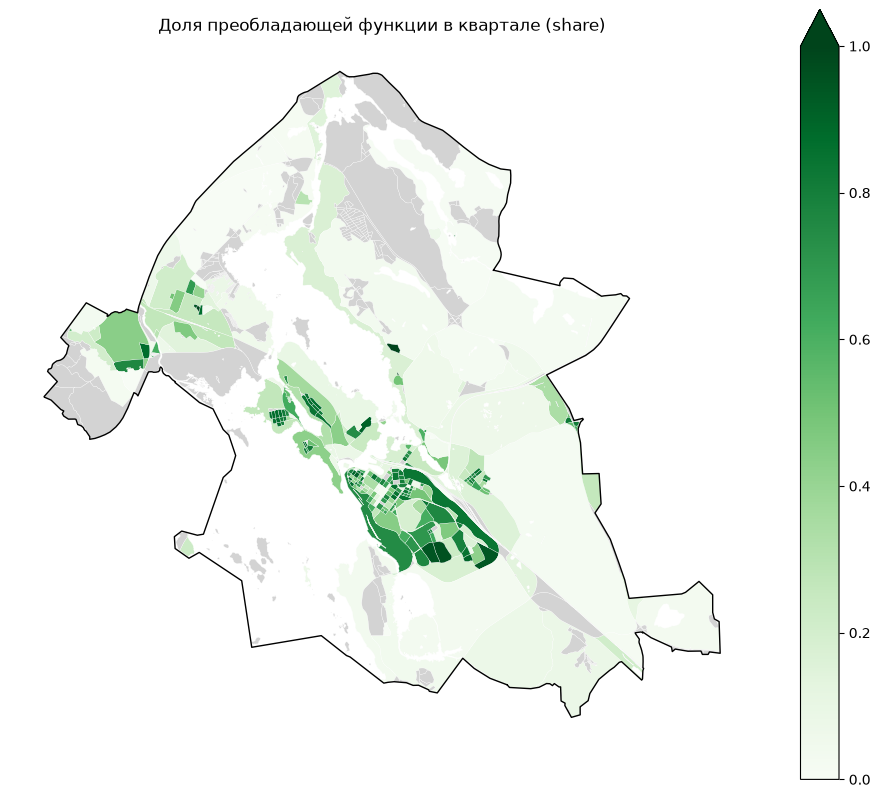

In [8]:
from blocksnet.enums import LandUse

blocks = ensure_block_index(read_geojson(PROCESSED_DIR / "blocks.geojson")).to_crs(metric_crs)
land_use_columns = [lu.value for lu in LandUse]
LAND_USE_SHARE_WARNING = 0.2  # ниже этой доли тип квартала считаем ненадёжным

print("Доли функций в первых кварталах с данными (0…1):")
display(
    blocks.loc[blocks["land_use"] != "no_data", land_use_columns + ["land_use", "share"]]
    .head(10)
    .round(2)
)

area_ha = blocks["site_area"] / 10_000
land_use_summary = pd.DataFrame(
    {
        "кварталов": blocks.groupby("land_use").size(),
        "площадь, га": area_ha.groupby(blocks["land_use"]).sum().round(1),
        "медианная доля share": blocks.groupby("land_use")["share"].median().round(2),
    }
)
display(land_use_summary.sort_values("площадь, га", ascending=False))

weak_land_use = (blocks["land_use"] != "no_data") & (blocks["share"] < LAND_USE_SHARE_WARNING)
print(
    f"Кварталов, где преобладающая функция занимает меньше {LAND_USE_SHARE_WARNING:.0%} площади:",
    int(weak_land_use.sum()),
)
print(
    "Их площадь, га:", round(float(area_ha[weak_land_use].sum()), 1),
    "из", round(float(area_ha.sum()), 1),
)

fig, ax = plt.subplots(figsize=(12, 10))
blocks.plot(
    "share",
    cmap="Greens",
    vmin=0,
    vmax=1,
    legend=True,
    ax=ax,
    edgecolor="white",
    linewidth=0.2,
    missing_kwds={"color": "lightgrey", "label": "нет данных"},
)
boundaries_metric.boundary.plot(ax=ax, color="black", linewidth=1)
ax.set_title("Доля преобладающей функции в квартале (share)")
ax.set_axis_off()
plt.show()

## Справочник метрик BlocksNet

Этот и два следующих раздела — справка, ничего не считают. Прочитайте их на остановке
перед расчётами, чтобы выбрать метрики. Описание сделано по коду установленной версии
BlocksNet 1.0.0a9 (`.venv/Lib/site-packages/blocksnet/analysis`).

**Главная идея BlocksNet.** Город режется на кварталы (участки между улицами, железными
дорогами и водой). Всё — здания, школы, население — «складывается» в кварталы, и метрики
считаются для каждого квартала. Поэтому почти любой показатель можно раскрасить на карте.

### Все группы метрик в BlocksNet (простыми словами)

| Группа | Функции | Что показывает | Единицы |
|---|---|---|---|
| **Плотность застройки** | `calculate_density_indicators` | Насколько плотно и высоко застроен квартал, сколько в нём жилья (`fsi`, `gsi`, `mxi`, `l`, `osr`) | безразмерные доли, этажи |
| **Площади застройки** | `calculate_development_indicators` | Пятно застройки, общая, жилая и нежилая площадь этажей | м² |
| **Морфотипы** | `get_spacematrix_morphotypes`, `get_strelka_morphotypes` | Тип застройки квартала: «частный сектор», «советский микрорайон», «центральная модель» и т.п. | категория (текст) |
| **Доступность** | `calculate_accessibility_matrix`, `median/mean/max_accessibility`, `area_accessibility`, `relative_accessibility` | Сколько минут идти из квартала до других кварталов | минуты |
| **Доступность функций** | `land_use_accessibility`, `land_use_accessibility_matrix` | Сколько минут до ближайших кварталов определённого назначения (жильё, работа, парки) | минуты |
| **Связность** | `calculate_connectivity` | Обратная величина доступности: `1 / время`. Чем больше, тем лучше квартал связан с городом | 1/мин |
| **Обеспеченность сервисами (конкурентная)** | `competitive_provision`, `provision_strong_total`, `provision_weak_total` | Хватает ли мест в школах/садах/поликлиниках жителям квартала, если жители «конкурируют» за места | доля 0…1, места |
| **Обеспеченность (разделяемая)** | `shared_provision` | Упрощённый вариант: сколько мест доступно в радиусе на одного жителя и какая нагрузка на учреждение | мест/чел., чел./место |
| **Сервисы** | `services_count`, `services_density`, `services_collocation` | Сколько сервисов в квартале, их плотность на площадь, какие сервисы часто стоят рядом | шт., шт./м², 0…1 |
| **Разнообразие** | `shannon_diversity` | Индекс Шеннона: насколько разнообразен набор сервисов в квартале (0 — один тип) | безразмерный, ≥0 |
| **Центральность** | `population_centrality`, `services_centrality` | Насколько квартал «центральный» — по населению и соседям или по сервисам, связности и разнообразию | 0…1 |
| **Функциональное использование** | `assign_land_use`, `calculate_land_use_shares`, `land_use_collocation`, `land_use_similarity`, `calculate_land_use_indicators` | Назначение квартала (жилой, деловой, рекреация…), доли назначений, какие назначения соседствуют, на какое назначение похож квартал по набору сервисов | категория, доли 0…1 |
| **Геометрия кварталов** | `calculate_area_length`, `calculate_aspect_ratio`, `calculate_radiuses`, `calculate_centerlines`, `calculate_centroids` | Площадь, периметр, вытянутость, вписанный/описанный радиус, длина осевой линии, координаты центра | м², м, безразмерный |
| **Свободные участки** | `get_vacant_areas` | Незастроенные участки, где потенциально можно что-то построить | м², полигоны |
| **Транспортные потоки** | `origin_destination_matrix`, `road_congestion` | Модель поездок между кварталами и загрузка улиц этими поездками | поездки (условные) |
| **Соцэкономика (уровень района/города)** | `SocioEconomicAggregator` и индикаторы `general`, `demographic`, `settlement`, `transport`, `economic`, `ecological`, `engineering`, `social` | Агрегаты для территории целиком: население, плотность, урбанизация, число и обеспеченность объектов (школы, больницы, парки…), инженерия, экология | разные: чел., км², шт., % |

Кроме анализа, в BlocksNet есть модули **машинного обучения** (предсказание назначения
кварталов, классификация улиц), **оптимизации** и **синтеза** застройки — это уже не
метрики, а инструменты для сценариев «что будет, если построить…».

### Все показатели из `pipeline.ipynb` (их повторяет этот ноутбук)

Ниже каждая колонка, которая появится в результатах. «Где» — раздел ноутбука и файл.

#### Кварталы и функциональное использование (разделы 3–4, `blocks.geojson`)

| Показатель | Что означает простыми словами | Единицы | Что узнаем о Выборге |
|---|---|---|---|
| `block_id` | Номер квартала | — | Ключ для соединения всех таблиц |
| `site_area` | Площадь квартала | м² (÷10 000 = га) | Где крупные кварталы (лес, промзоны, порт), а где мелкая сетка улиц (исторический центр) |
| `residential`, `business`, `recreation`, `industrial`, `transport`, `special`, `agriculture` | Какая доля площади квартала занята зоной этого типа по OSM `landuse` | доля 0…1 | Насколько квартал «смешанный» |
| `land_use` | Преобладающее назначение квартала (тип с наибольшей долей) | категория | Карта функционального зонирования: жильё, промышленность, зелень |
| `share` | Доля площади, которую занимает преобладающее назначение | доля 0…1 | Чистая ли зона (≈1) или смешанная (0,3–0,5) |

#### Доступность (раздел 6, `accessibility_matrix.csv`, `median_time_min.csv`)

| Показатель | Что означает | Единицы | Что узнаем |
|---|---|---|---|
| Матрица доступности `acc_mx` | Таблица «из квартала A в квартал B — столько минут пешком» по пешеходному графу, 5 км/ч | минуты; `inf` = маршрута нет | Основа для всех расчётов обеспеченности и доступности |
| `median_time_min` | Медианное время пешком от квартала до всех остальных | минуты | Какие кварталы «в центре событий», а какие на отшибе |
| Доля пар без маршрута | Сколько пар кварталов не соединены пешеходным графом | % | Разрывы сети: острова, вода, железная дорога, закрытые территории |

#### Здания и население (раздел 7, `buildings_blocks.geojson`)

| Показатель | Что означает | Единицы | Что узнаем |
|---|---|---|---|
| `footprint_area` | Пятно застройки — площадь, которую здания занимают на земле | м² | Где земля плотно занята зданиями |
| `build_floor_area` | Суммарная площадь всех этажей = пятно × этажность | м² | Объём застройки квартала |
| `living_area` | Жилая площадь = 90 % площади этажей жилых зданий | м² | Где сосредоточено жильё |
| `non_living_area` | Нежилая площадь = все этажи минус жилая | м² | Где офисы, магазины, производство |
| `population` | Оценка жителей = жилая площадь ÷ 30 м² на человека (минимум 1 на жилой дом) | человек | Где живут люди; от этого считается спрос на школы |
| `count` | Число зданий в квартале | шт. | Мелкая или крупная застройка |
| `is_living` | Число жилых зданий в квартале (после суммирования) | шт. | Сколько домов жилые |
| `number_of_floors` | **Сумма** этажей всех зданий квартала, а не средняя этажность | этажи (сумма) | Для выводов не используйте, смотрите `l` |

#### Школы (раздел 8, `schools_blocks.geojson`)

| Показатель | Что означает | Единицы | Что узнаем |
|---|---|---|---|
| `capacity` | Суммарная вместимость школ квартала. Если в OSM вместимость не указана — подставляется минимум из справочника BlocksNet: **250 мест** | места | Где сосредоточены школьные места |
| `count` | Число школ в квартале | шт. | Где школы есть вообще |

#### Обеспеченность школами (раздел 9, `provision.csv`, `provision_links.csv`)

Норматив BlocksNet для школы: **120 мест на 1000 жителей**, доступность **15 минут** пешком.

| Показатель | Что означает | Единицы | Что узнаем |
|---|---|---|---|
| `demand` | Сколько школьных мест нужно кварталу: население ÷ 1000 × 120, округление вверх | места | Потребность в школах |
| `demand_within` | Сколько из потребности закрыто школами в пределах 15 минут | места | Удовлетворённый спрос |
| `demand_without` | Сколько закрыто школами дальше 15 минут | места | Спрос, закрытый «с натяжкой» |
| `demand_left` | Сколько мест так и не нашлось | места | Нехватка — где нужна новая школа |
| `capacity_within`, `capacity_without` | Сколько мест школы квартала отдала жителям ближе / дальше 15 минут | места | Кого обслуживает школа |
| `capacity_left` | Сколько мест в школе осталось незанятыми | места | Где школы недогружены |
| `provision_strong` | Доля потребности, закрытая в пределах 15 минут = `demand_within / demand` | доля 0…1 (1 = 100 %) | **Главная карта**: зелёные — школ хватает рядом, красные — дефицит |
| `provision_weak` | То же, но вместе со школами дальше 15 минут | доля 0…1 | Насколько дефицит смягчается, если ходить дальше |
| `provision_strong_total`, `provision_weak_total` | Те же доли по всему городу сразу | доля 0…1 | Одна цифра «обеспеченность Выборга школами» |
| `provision_links`: `source`, `target`, `value` | Сколько детей (`value`) из квартала `source` распределено в школы квартала `target` | места | Какие школы обслуживают какие районы |

#### Плотность застройки (раздел 10, `density.csv`)

| Показатель | Формула | Единицы | Как читать | Что узнаем |
|---|---|---|---|---|
| `fsi` (Floor Space Index, интенсивность) | площадь этажей ÷ площадь квартала | м²/м², безразмерный, ≥0 | 0,1 — частный сектор; 0,5–1 — средняя застройка; >1,5 — плотный центр | Где город «насыщен» застройкой |
| `gsi` (Ground Space Index, застроенность) | пятно застройки ÷ площадь квартала | доля 0…1 | 0,1 — много свободной земли; 0,4+ — сплошная застройка | Где почти нет дворов и зелени |
| `mxi` (Mixed-use Index, доля жилья) | жилая площадь ÷ площадь этажей | доля 0…1 | 0 — нежилой; ~0,5 — смешанный; ~0,9 — чисто жилой | Где живут, а где работают |
| `l` (средняя этажность) | площадь этажей ÷ пятно застройки, не меньше 1 | этажи | 1–3 малоэтажная, 4–8 средняя, 9+ высотная | Высотный профиль города |
| `osr` (Open Space Ratio, открытость) | незастроенная площадь ÷ площадь этажей | м²/м² | Сколько м² открытой земли приходится на 1 м² площади зданий | Хватает ли дворов, места для детских площадок |
| `share_living` | жилая площадь ÷ пятно застройки | м²/м² | **Не доля**, может быть больше 1: «сколько этажей жилья» стоит на пятне | Насыщенность квартала жильём |
| `share_non_living` | нежилая площадь ÷ пятно застройки | м²/м² | Тоже может быть больше 1 | Насыщенность нежилыми функциями |

#### Морфотипы (разделы 11–12)

| Показатель | Что означает | Единицы | Что узнаем |
|---|---|---|---|
| `cluster` | Номер группы похожих кварталов (KMeans по `l`, `fsi`, `mxi` и т.д., до 11 групп) | номер | Технический номер кластера |
| `morphotype_spacematrix` | Название группы из трёх слов по медианам группы: этажность (`low-rise` <3, `mid-rise` 3–6, `high-mid-rise` 6–10, `high-rise` 10–17, `tower` 17+), плотность (`low-density` при `fsi`<1, `high-density` при `fsi`≥2, между 1 и 2 слово не пишется) и функция (`non-residential` при `mxi`<0,22, `mixed-use` до 0,55, `residential` выше) | категория | Статистическая типология застройки именно этого города |
| `morphotype_strelka` | Тип по жёстким правилам КБ Стрелка: малоэтажная (`individual residential`, `low-rise model`, нежилая), среднеэтажная (`mid-rise`, `mid-rise block`, `mid-rise microdistrict`, `central model`, нежилая), высотная (`high-rise soviet microdistrict` при `fsi`≤1,5, `high-rise modern microdistrict`, нежилая) | категория | Понятная карта: частный сектор, советские микрорайоны, историческая квартальная застройка центра |

#### Area accessibility (раздел 13, `area_accessibility.csv`)

| Показатель | Что означает | Единицы | Что узнаем |
|---|---|---|---|
| `area_accessibility` | Среднее время пешком из квартала до остальных, где большие кварталы весят больше: Σ(время × площадь) ÷ Σ площадей | минуты (меньше — лучше) | Насколько квартал близок «ко всей территории» города; окраины и отрезанные водой районы будут хуже |

#### Сводка (раздел 15, `summary.csv`)

| Показатель | Единицы | Что это |
|---|---|---|
| `blocks_count`, `buildings_count`, `schools_count` | шт. | Сколько кварталов, зданий и школ |
| `population_total` | человек | Оценка населения города |
| `school_capacity_total` | места | Всего мест в школах (с подставленными значениями) |
| `median_travel_time_min` | минуты | Типичное время пешком между двумя кварталами |
| `share_unreachable_pairs` | доля 0…1 | Доля пар кварталов без пешеходного маршрута |
| `provision_strong_mean`, `provision_weak_mean` | доля 0…1 | Средняя по кварталам обеспеченность школами |
| `area_accessibility_median_min` | минуты | Типичная area accessibility |

### Что важно знать перед расчётом (найдено в коде BlocksNet)

- **`provision_weak` здесь совпадёт с `provision_strong`.** `competitive_provision` по
  умолчанию ищет школы только в пределах одного норматива (`max_depth=1`, то есть 15 минут),
  поэтому `demand_without` и `capacity_without` будут нулями. Чтобы `provision_weak` что-то
  показывала, нужно передать, например, `max_depth=2` (поиск до 30 минут).
- **Пустые кварталы дают пропуски.** Где нет зданий, `fsi`, `mxi`, `l` получаются как 0 ÷ 0,
  а `osr` — как деление на ноль (`inf`). Где нет жителей, `provision_strong` = 0 ÷ 0 (пропуск).
  Это не ошибка: для таких кварталов показатель не имеет смысла.
- **Одна недостижимая пара портит `area_accessibility`.** Если из квартала хотя бы до одного
  квартала нет маршрута (`inf`), сумма становится `inf`, и в итоговом GeoJSON у квартала
  будет пропуск. Смотрите на долю пар без маршрута в разделе 6.
- **Население — оценка.** Жилая площадь = 90 % площади этажей жилых зданий, на человека
  30 м². Здание считается жилым только по тегу `building` (`residential`, `house`,
  `apartments`, `detached`, `terrace`, `dormitory`); дома с тегом `yes` будут нежилыми.
  Без этажности в OSM дом считается одноэтажным — население многоэтажек занизится.
- **Вместимость школ — частично подставлена.** Без тега `capacity` школа получает 250 мест.
- **Морфотипы считаются только для застроенных кварталов** (`fsi` > 0); у остальных — `no_data`.

### Какие вопросы о Выборге помогут решить эти метрики

1. **Где не хватает школ в пешей доступности?** — карта `provision_strong` и `demand_left`.
2. **Где школы перегружены или, наоборот, полупустые?** — `capacity_left` и `provision_links`.
3. **Где плотный исторический центр, где советские микрорайоны, где частный сектор?** —
   `morphotype_strelka`, `fsi`, `gsi`, `l`.
4. **Где люди живут, а где только работают?** — `mxi`, `land_use`, `population`.
5. **Хватает ли во дворах открытого пространства?** — `osr` и `gsi`.
6. **Какие районы отрезаны водой и железной дорогой?** — `area_accessibility`,
   `median_time_min`, доля пар без маршрута.

### Что можно добавить к pipeline на этой остановке

- Детские сады (`kindergarten`: 61 место на 1000 жителей, 7 минут) или поликлиники —
  тем же способом, что и школы.
- `calculate_connectivity` — связность квартала (1 ÷ время доступности).
- `land_use_accessibility` — время до ближайших парков (`recreation`) или мест работы.
- `calculate_aspect_ratio` и `calculate_area_length` — форма и размер кварталов.
- `get_vacant_areas` — свободные участки, где можно разместить новую школу.

## STOP — остановка перед расчётами

**Не запускайте следующие ячейки.** Сначала посмотрите карту кварталов и проверьте:

- граница Выборга на месте;
- кварталы выглядят как кварталы, а не как случайные обрывки;
- вода и крупные дороги не «разрезали» город странным образом;
- количество кварталов и их площадь выглядят правдоподобно.

Теперь мы согласуем метрики. По умолчанию ноутбук готов повторить `pipeline.ipynb`:

- доступность (матрица времени в минутах);
- население и параметры зданий;
- вместимость школ;
- конкурентная обеспеченность школами;
- плотностные показатели `fsi`, `gsi`, `mxi`, `l`, `osr`;
- морфотипы Spacematrix и Strelka;
- area accessibility.

На остановке можно добавить, например, детские сады или поликлиники. Для этого нужно
будет добавить загрузку и агрегацию соответствующего сервиса. Пока по умолчанию оставлена
только школа, как в `pipeline.ipynb`.

Когда метрики согласованы, поменяйте `RUN_CALCULATIONS = True` в ячейке с константами
и запустите расчётные ячейки по порядку.

In [9]:
if RUN_CALCULATIONS:
    print("Расчёты включены. Можно идти дальше.")
else:
    print("STOP: расчёты выключены.")
    print("Посмотрите карту кварталов и согласуйте метрики.")
    print("Потом поменяйте RUN_CALCULATIONS = True в ячейке с константами.")


Расчёты включены. Можно идти дальше.


In [10]:
assert RUN_CALCULATIONS, (
    "STOP: расчёты отключены. Сначала посмотрите кварталы и согласуйте метрики. "
    "Потом поменяйте RUN_CALCULATIONS = True в ячейке с константами."
)
print("Продолжаем: расчёты включены.")


Продолжаем: расчёты включены.


## 5. Пешеходный граф

Выбранный граф: **пешеходная сеть OpenStreetMap**. Источник — OpenStreetMap / Overpass API.
Способ передвижения — пешком, средняя скорость 5 км/ч. Время хранится в минутах в атрибуте
рёбер `time_min`. Интермодальный граф не строим.

BlocksNet скачивает граф через IduEdu/OSMnx и сохраняет его в `cache/walk_graph.pickle`.
При следующем запуске граф читается с диска, если совпадают территория, тип графа и скорость.

In [11]:
from blocksnet.relations import get_accessibility_graph

boundaries, boundaries_metric, metric_crs = load_boundary_and_crs()

graph_path = CACHE_DIR / "walk_graph.pickle"
graph_metadata_path = CACHE_DIR / "metadata.json"
graph_metadata = {
    "territory_osm_id": TERRITORY_OSM_ID,
    "graph_type": GRAPH_TYPE,
    "walk_speed_kmh": WALK_SPEED_KMH,
    "created_at": pd.Timestamp.now().isoformat(),
    "blocksnet_version": md.version("blocksnet"),
}

same_cache = False
if USE_CACHE and graph_path.exists() and graph_metadata_path.exists():
    old_metadata = json.loads(graph_metadata_path.read_text(encoding="utf-8"))
    same_cache = (
        old_metadata.get("territory_osm_id") == TERRITORY_OSM_ID
        and old_metadata.get("graph_type") == GRAPH_TYPE
        and (
            GRAPH_TYPE != "walk"
            or abs(float(old_metadata.get("walk_speed_kmh", -1)) - WALK_SPEED_KMH) < 0.01
        )
    )

if same_cache:
    with open(graph_path, "rb") as file:
        graph = pickle.load(file)
    print("Граф загружен из кэша.")
else:
    graph_kwargs = {}
    if GRAPH_TYPE == "walk":
        graph_kwargs["walk_speed"] = WALK_SPEED_KMH * 1000 / 60  # метров в минуту
    graph = get_accessibility_graph(boundaries, GRAPH_TYPE, **graph_kwargs)
    with open(graph_path, "wb") as file:
        pickle.dump(graph, file, protocol=pickle.HIGHEST_PROTOCOL)
    graph_metadata_path.write_text(
        json.dumps(graph_metadata, ensure_ascii=False, indent=2),
        encoding="utf-8",
    )
    print("Граф скачан из OSM и сохранён.")

crs_ok = graph.graph.get("crs") is not None
nodes_ok = all(("x" in data and "y" in data) for _, data in graph.nodes(data=True))
edges_ok = all("time_min" in data for _, _, data in graph.edges(data=True))

print("Узлов:", graph.number_of_nodes())
print("Рёбер:", graph.number_of_edges())
print("CRS в графе:", graph.graph.get("crs"))
print("Есть x/y у узлов:", nodes_ok)
print("Есть time_min у рёбер:", edges_ok)

assert crs_ok and nodes_ok and edges_ok, "Граф не прошёл проверку структуры."


Граф загружен из кэша.
Узлов: 19944
Рёбер: 51766
CRS в графе: 32635
Есть x/y у узлов: True
Есть time_min у рёбер: True


## 6. Матрица времени между кварталами

Матрица `n × n`: на пересечении строки «квартал A» и столбца «квартал B» — время в минутах
из A в B. Диагональ около нуля. Значения `inf` означают, что маршрут не найден.

Считаем по пешеходному графу. Матрица сохраняется в CSV, потому что это таблица, а не
пространственный слой.

Матрица загружена из кэша.
Размер матрицы: (1143, 1143)
Медианное время, минут: 106.46
Доля пар без маршрута: 0.0 %
Диагональ: min / median / max: 0.0 0.0 0.0


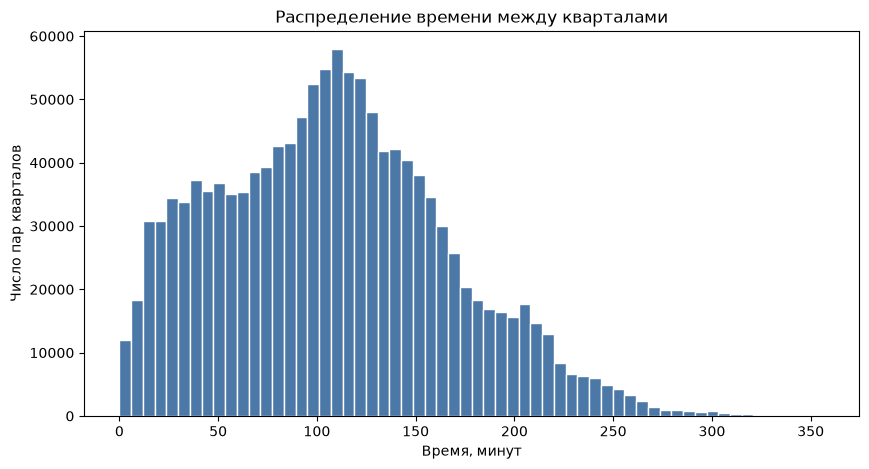

block_id,1,2,3,4,5
block_id,,,,,
1,0.000000,0.000000,9.888295,25.529148,161.04674
2,0.000000,0.000000,10.168168,25.809021,161.32660
3,9.888295,10.168168,0.000000,19.915310,170.38290
4,25.529148,25.809021,19.915310,0.000000,183.19376
5,161.046740,161.326600,170.382900,183.193760,0.00000


In [12]:
from blocksnet.relations import calculate_accessibility_matrix

blocks = ensure_block_index(read_geojson(PROCESSED_DIR / "blocks.geojson")).to_crs(metric_crs)
matrix_path = RESULTS_DIR / "accessibility_matrix.csv"
matrix_metadata_path = RESULTS_DIR / "accessibility_matrix_meta.json"

matrix_metadata = {
    "territory_osm_id": TERRITORY_OSM_ID,
    "graph_type": GRAPH_TYPE,
    "walk_speed_kmh": WALK_SPEED_KMH,
    "blocks_count": len(blocks),
    "created_at": pd.Timestamp.now().isoformat(),
}

same_matrix_cache = False
if USE_CACHE and matrix_path.exists() and matrix_metadata_path.exists():
    old_matrix_metadata = json.loads(matrix_metadata_path.read_text(encoding="utf-8"))
    same_matrix_cache = (
        old_matrix_metadata.get("territory_osm_id") == TERRITORY_OSM_ID
        and old_matrix_metadata.get("graph_type") == GRAPH_TYPE
        and old_matrix_metadata.get("blocks_count") == len(blocks)
        and abs(float(old_matrix_metadata.get("walk_speed_kmh", -1)) - WALK_SPEED_KMH) < 0.01
    )

if same_matrix_cache:
    acc_mx = pd.read_csv(matrix_path, index_col=0)
    acc_mx.index = acc_mx.index.astype(int)
    acc_mx.columns = acc_mx.columns.astype(int)
    acc_mx = acc_mx.reindex(index=blocks.index, columns=blocks.index)
    print("Матрица загружена из кэша.")
else:
    acc_mx = calculate_accessibility_matrix(blocks, graph, dtype=np.float32)
    acc_mx.index = acc_mx.index.astype(int)
    acc_mx.columns = acc_mx.columns.astype(int)
    acc_mx.to_csv(matrix_path, index=True)
    matrix_metadata_path.write_text(
        json.dumps(matrix_metadata, ensure_ascii=False, indent=2),
        encoding="utf-8",
    )
    print("Матрица рассчитана и сохранена.")

assert acc_mx.shape == (len(blocks), len(blocks)), "Размер матрицы не совпадает с числом кварталов."

values = acc_mx.values
finite_values = values[np.isfinite(values)]
median_time = float(np.median(finite_values))
share_inf = float(np.isinf(values).mean())
diagonal = np.diag(values)

print("Размер матрицы:", acc_mx.shape)
print("Медианное время, минут:", round(median_time, 2))
print("Доля пар без маршрута:", round(share_inf * 100, 2), "%")
print("Диагональ: min / median / max:", round(float(np.min(diagonal)), 2), round(float(np.median(diagonal)), 2), round(float(np.max(diagonal)), 2))

median_time_by_block = pd.DataFrame(
    {"median_time_min": acc_mx.replace([np.inf], np.nan).median(axis=1)}
)
median_time_by_block.index.name = "block_id"
median_time_by_block.to_csv(RESULTS_DIR / "median_time_min.csv")

fig, ax = plt.subplots(figsize=(10, 5))
ax.hist(finite_values, bins=60, color="#4c78a8", edgecolor="white")
ax.set_title("Распределение времени между кварталами")
ax.set_xlabel("Время, минут")
ax.set_ylabel("Число пар кварталов")
plt.show()

display(acc_mx.iloc[:5, :5])


### 6.1. Карта медианного времени

Для каждого квартала — медианное время пешком до всех остальных кварталов, в минутах.
Тёмные кварталы ближе «ко всему городу», светлые — на отшибе.

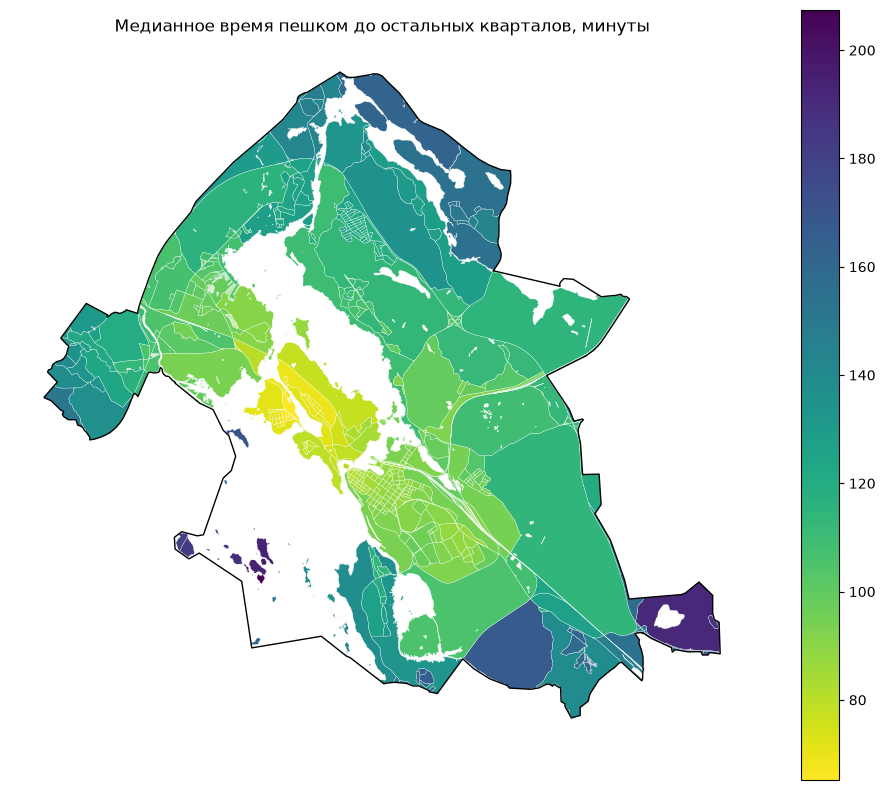

,median_time_min
count,1143.0
mean,109.4
std,26.5
min,65.2
25%,90.8
50%,101.2
75%,122.1
max,207.4


In [13]:
median_time_by_block = pd.read_csv(RESULTS_DIR / "median_time_min.csv", index_col=0)
median_time_by_block.index = median_time_by_block.index.astype(int)

fig, ax = plt.subplots(figsize=(12, 10))
blocks.join(median_time_by_block)[["geometry", "median_time_min"]].plot(
    "median_time_min",
    cmap="viridis_r",
    legend=True,
    ax=ax,
    edgecolor="white",
    linewidth=0.2,
    missing_kwds={"color": "lightgrey", "label": "нет маршрута"},
)
boundaries_metric.boundary.plot(ax=ax, color="black", linewidth=1)
ax.set_title("Медианное время пешком до остальных кварталов, минуты")
ax.set_axis_off()
plt.show()

display(median_time_by_block.describe().round(1))

## 7. Здания

Загружаем здания из OSM, определяем жилые и этажность, заполняем пропуски по правилам
`pipeline.ipynb` и агрегируем в кварталы. Получаются оценки населения и площадей.

**Важно:** это оценка по открытым данным, а не официальная статистика. Пропущенная
этажность по умолчанию заменяется на 1 этаж, а жилая площадь — на 30 м² на человека.

2026-10-30 00:10:56.324 | WARNING  | blocksnet.preprocessing.imputing.buildings.schemas:_before_validate:21 - Column footprint_area not found and will be initialized as None
2026-10-30 00:10:56.324 | WARNING  | blocksnet.preprocessing.imputing.buildings.schemas:_before_validate:21 - Column build_floor_area not found and will be initialized as None
2026-10-30 00:10:56.336 | WARNING  | blocksnet.preprocessing.imputing.buildings.schemas:_before_validate:21 - Column living_area not found and will be initialized as None
2026-10-30 00:10:56.336 | WARNING  | blocksnet.preprocessing.imputing.buildings.schemas:_before_validate:21 - Column non_living_area not found and will be initialized as None
2026-10-30 00:10:56.338 | WARNING  | blocksnet.preprocessing.imputing.buildings.schemas:_before_validate:21 - Column population not found and will be initialized as None


Здания загружены из кэша.


2026-10-30 00:10:57.457 | INFO     | blocksnet.blocks.aggregation.core:_preprocess_input:12 - Preprocessing input
2026-10-30 00:10:57.472 | INFO     | blocksnet.blocks.aggregation.core:aggregate_objects:41 - Aggregating objects


Сохранено: D:\ai\python-package-boilerplate-main\python-package-boilerplate-main\examples\data\vyborg\processed\buildings_imputed.geojson
Сохранено: D:\ai\python-package-boilerplate-main\python-package-boilerplate-main\examples\data\vyborg\processed\buildings_blocks.geojson
Зданий: 14536
Оценка населения: 71811
Жилых зданий: 1312
Этажность из OSM: 1936 | подставлено значение по умолчанию: 12600


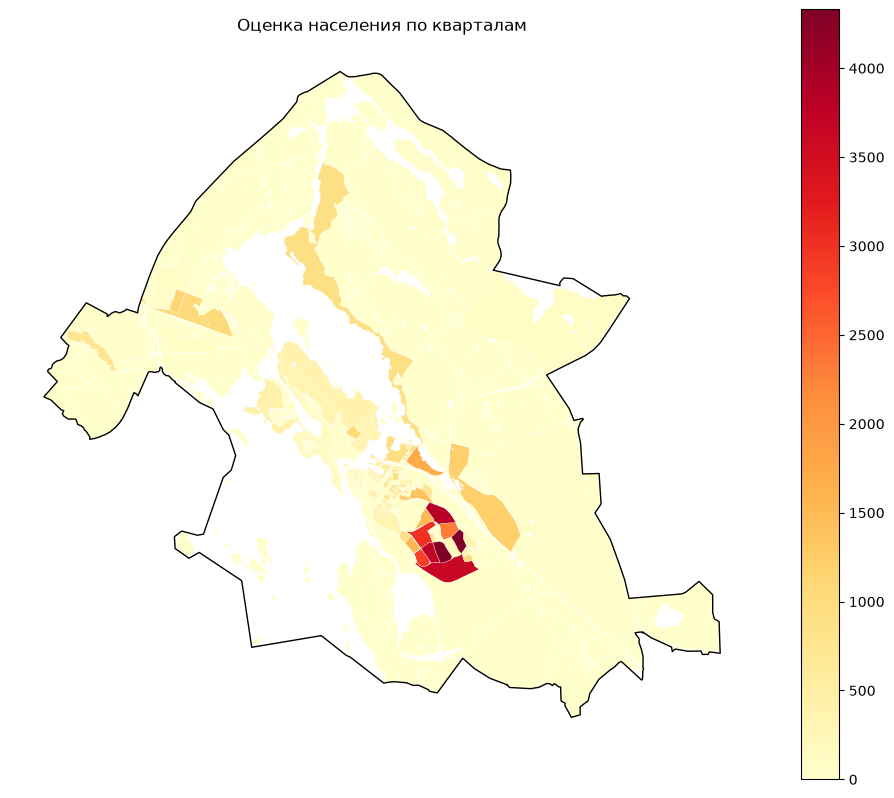

,count,is_living,floors_from_osm,population,footprint_area,build_floor_area,living_area,non_living_area
count,406.00,406.00,406.00,406.00,406.00,406.00,406.00,406.00
mean,35.79,3.23,4.77,176.87,7550.11,13198.12,5355.63,7842.50
std,97.37,7.46,8.62,544.57,18281.19,28418.77,16405.94,19751.55
min,1.00,0.00,0.00,0.00,6.85,6.85,0.00,6.85
25%,6.00,0.00,0.00,0.00,1010.50,1062.35,0.00,873.29
50%,12.00,0.00,1.00,0.00,2296.79,2721.19,0.00,1898.86
75%,24.00,4.00,6.00,85.50,5979.02,12047.40,2605.94,6046.29
max,1412.00,65.00,55.00,4331.00,213290.85,228287.66,130238.85,228287.66


In [14]:
from blocksnet.blocks.aggregation import aggregate_objects
from blocksnet.preprocessing.imputing import impute_buildings

boundaries, boundaries_metric, metric_crs = load_boundary_and_crs()
blocks = ensure_block_index(read_geojson(PROCESSED_DIR / "blocks.geojson")).to_crs(metric_crs)

buildings_path = RAW_DIR / "buildings_raw.geojson"
if USE_CACHE and buildings_path.exists():
    buildings = read_geojson(buildings_path)
    print("Здания загружены из кэша.")
else:
    buildings = ox.features_from_polygon(
        boundaries.to_crs(4326).union_all(),
        tags={"building": True},
    )
    buildings = buildings[buildings.geom_type.isin(["Polygon", "MultiPolygon"])].copy()
    buildings = buildings.reset_index(drop=True)
    if "building" not in buildings.columns:
        buildings["building"] = "yes"
    buildings["building"] = buildings["building"].map(_stringify)
    is_living_tags = ["residential", "house", "apartments", "detached", "terrace", "dormitory"]
    buildings["is_living"] = buildings["building"].isin(is_living_tags)
    levels = (
        buildings["building:levels"]
        if "building:levels" in buildings.columns
        else pd.Series(np.nan, index=buildings.index)
    )
    buildings["number_of_floors"] = pd.to_numeric(levels, errors="coerce")
    buildings = buildings[["geometry", "building", "is_living", "number_of_floors"]]
    write_geojson(buildings, buildings_path)
    print("Здания скачаны из OSM.")

if "is_living" not in buildings.columns:
    buildings["is_living"] = False
buildings["is_living"] = buildings["is_living"].map(
    lambda value: value.strip().lower() in {"true", "1", "yes"} if isinstance(value, str) else bool(value)
)
if "number_of_floors" not in buildings.columns:
    buildings["number_of_floors"] = np.nan
buildings["number_of_floors"] = pd.to_numeric(buildings["number_of_floors"], errors="coerce")
buildings = buildings.to_crs(metric_crs)

if len(buildings) == 0:
    raise ValueError("В OSM не найдено зданий.")

# impute_buildings оставляет только свои колонки, поэтому отметку об источнике
# этажности запоминаем заранее и возвращаем после заполнения пропусков.
floors_from_osm = buildings["number_of_floors"].fillna(0) > 0
buildings = impute_buildings(
    buildings,
    default_number_of_floors=DEFAULT_NUMBER_OF_FLOORS,
    default_living_demand=LIVING_DEMAND_M2_PER_PERSON,
)
buildings["floors_from_osm"] = floors_from_osm
write_geojson(buildings, PROCESSED_DIR / "buildings_imputed.geojson")

buildings_blocks = aggregate_objects(blocks, buildings.copy())[0]
buildings_blocks.index.name = "block_id"
buildings_blocks["site_area"] = buildings_blocks.area.astype(float)
write_geojson(buildings_blocks, PROCESSED_DIR / "buildings_blocks.geojson")

print("Зданий:", len(buildings))
print("Оценка населения:", int(round(buildings["population"].sum())))
print("Жилых зданий:", int(buildings["is_living"].sum()))
print(
    "Этажность из OSM:", int(buildings["floors_from_osm"].sum()),
    "| подставлено значение по умолчанию:", int((~buildings["floors_from_osm"]).sum()),
)

fig, ax = plt.subplots(figsize=(12, 10))
buildings_blocks.plot(
    "population",
    cmap="YlOrRd",
    legend=True,
    ax=ax,
    edgecolor="white",
    linewidth=0.2,
    missing_kwds={"color": "lightgrey"},
)
boundaries_metric.boundary.plot(ax=ax, color="black", linewidth=1)
ax.set_title("Оценка населения по кварталам")
ax.set_axis_off()
plt.show()

building_columns = [
    "count", "is_living", "floors_from_osm", "population",
    "footprint_area", "build_floor_area", "living_area", "non_living_area",
]
display(buildings_blocks.loc[buildings_blocks["count"] > 0, building_columns].describe().round(2))

### 7.1. Площади застройки и что в них оценено

| Показатель | Откуда | Единицы |
|---|---|---|
| `count`, `footprint_area` | из OSM: число зданий и площадь их контуров | шт., м² |
| `floors_from_osm` | сколько зданий квартала имеют этажность в OSM | шт. |
| `build_floor_area` | **оценка**: пятно × этажность (без этажности — 1 этаж) | м² |
| `living_area`, `non_living_area` | **оценка**: 90 % площади этажей жилых зданий — жилая, остальное — нежилая | м² |
| `population` | **оценка**: жилая площадь ÷ 30 м² на человека | человек |
| `is_living` | сколько зданий квартала жилые по тегу `building` | шт. |

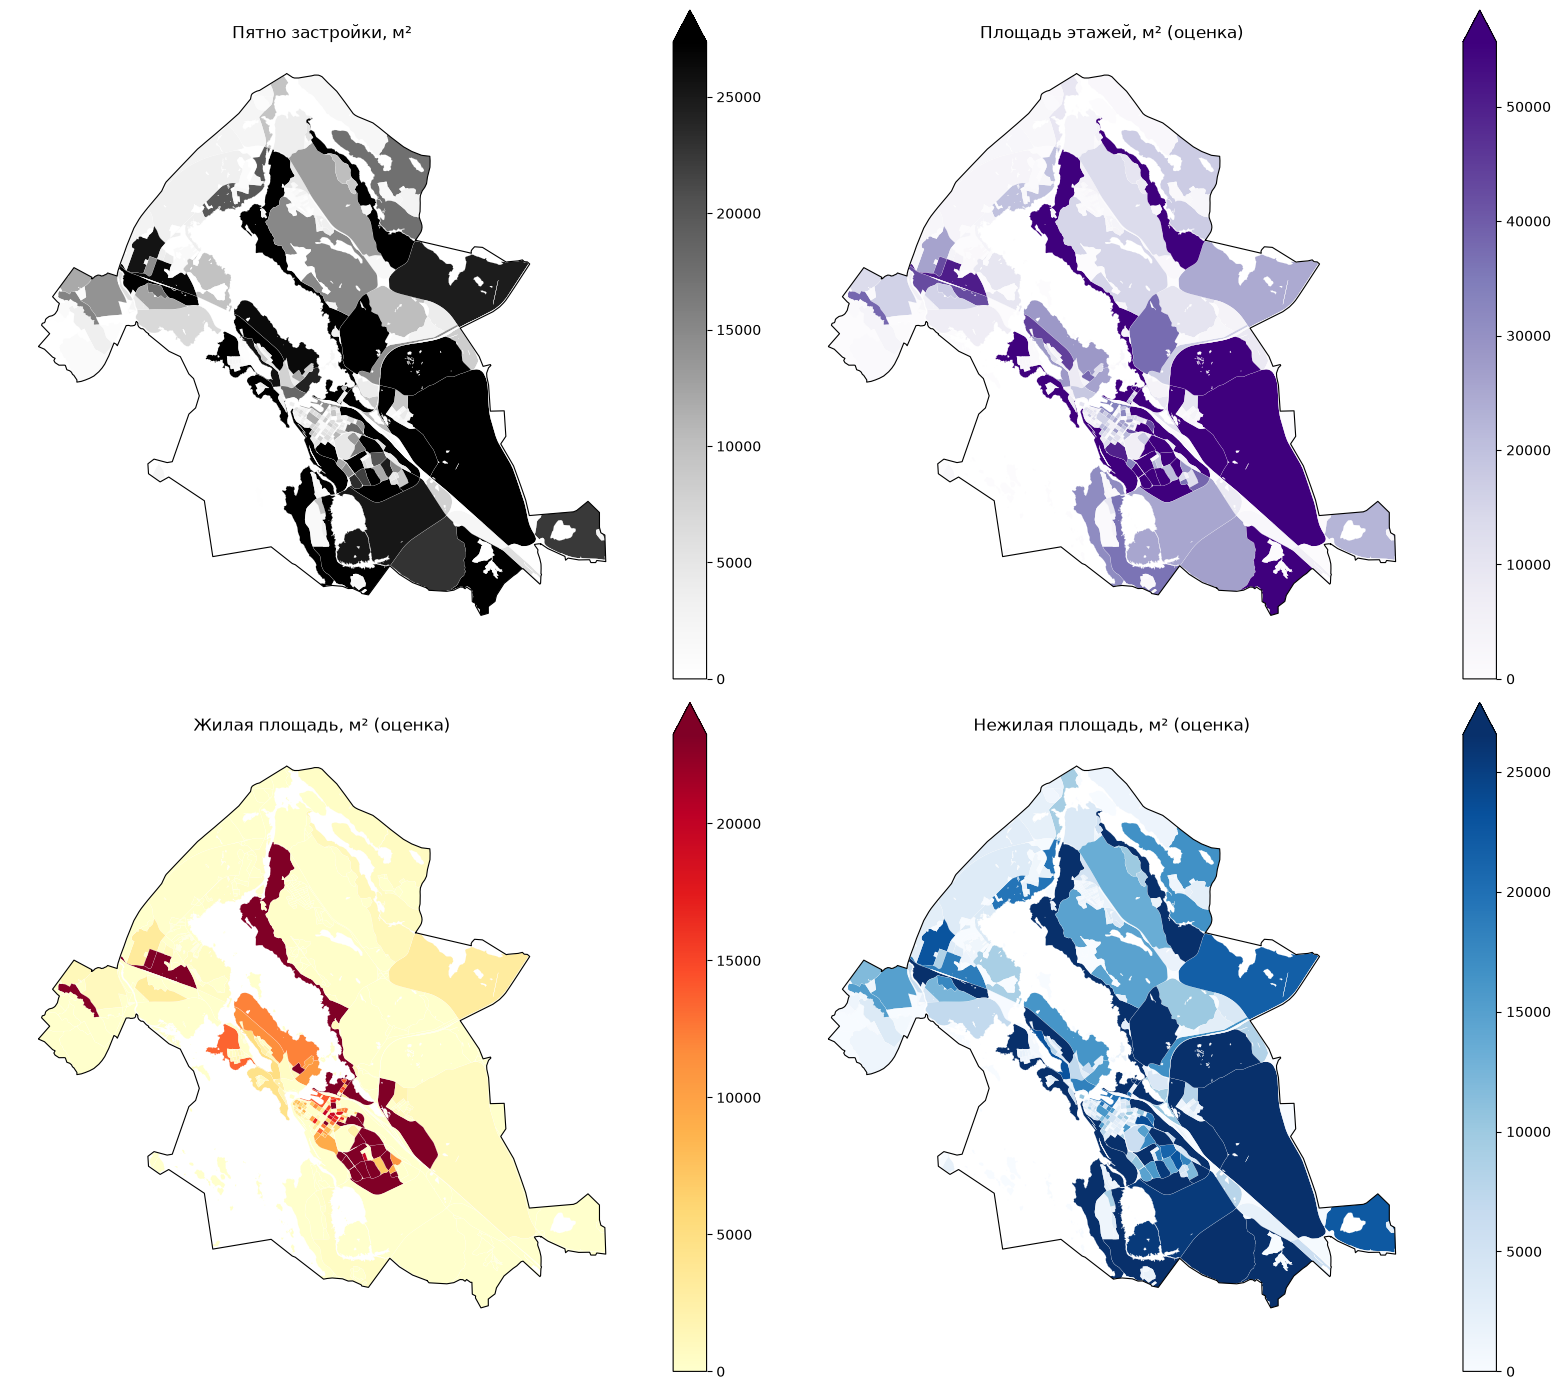

Доля зданий с этажностью из OSM: 13.3%
Чем меньше эта доля, тем сильнее занижены площадь этажей и население многоэтажек.
Несколько зданий после заполнения пропусков (как buildings.sample в pipeline.ipynb):


,is_living,number_of_floors,footprint_area,build_floor_area,living_area,non_living_area,population,floors_from_osm
5341,False,1.0,119.3,119.3,0.0,119.3,NaN,False
2065,False,1.0,430.2,430.2,0.0,430.2,NaN,True
14343,False,1.0,69.8,69.8,0.0,69.8,NaN,False
10320,False,1.0,66.9,66.9,0.0,66.9,NaN,False
4036,False,1.0,33.6,33.6,0.0,33.6,NaN,False


In [15]:
area_maps = [
    ("footprint_area", "Пятно застройки, м²", "Greys"),
    ("build_floor_area", "Площадь этажей, м² (оценка)", "Purples"),
    ("living_area", "Жилая площадь, м² (оценка)", "YlOrRd"),
    ("non_living_area", "Нежилая площадь, м² (оценка)", "Blues"),
]
fig, axes = plt.subplots(2, 2, figsize=(16, 14))
for ax, (column, title, cmap) in zip(axes.flat, area_maps):
    buildings_blocks.plot(
        column,
        cmap=cmap,
        legend=True,
        ax=ax,
        edgecolor="white",
        linewidth=0.1,
        vmax=buildings_blocks[column].quantile(0.98),
    )
    boundaries_metric.boundary.plot(ax=ax, color="black", linewidth=0.8)
    ax.set_title(title)
    ax.set_axis_off()
plt.tight_layout()
plt.show()

floors_share = buildings_blocks["floors_from_osm"].sum() / buildings_blocks["count"].sum()
print(f"Доля зданий с этажностью из OSM: {floors_share:.1%}")
print("Чем меньше эта доля, тем сильнее занижены площадь этажей и население многоэтажек.")

print("Несколько зданий после заполнения пропусков (как buildings.sample в pipeline.ipynb):")
display(buildings.drop(columns="geometry").sample(5, random_state=1).round(1))

## 8. Школы

Загружаем школы из OSM (`amenity=school`), заполняем пропущенную вместимость минимальным
нормативом BlocksNet и агрегируем в кварталы.

Если в OSM у школы не указана вместимость, BlocksNet подставит минимальное значение из
справочника. Это заметное допущение; в выводах его нужно упомянуть.

2026-10-30 00:11:01.590 | INFO     | blocksnet.blocks.aggregation.core:_preprocess_input:12 - Preprocessing input
2026-10-30 00:11:01.590 | INFO     | blocksnet.blocks.aggregation.core:aggregate_objects:41 - Aggregating objects


Школы загружены из кэша.
Сохранено: D:\ai\python-package-boilerplate-main\python-package-boilerplate-main\examples\data\vyborg\processed\schools_imputed.geojson
Сохранено: D:\ai\python-package-boilerplate-main\python-package-boilerplate-main\examples\data\vyborg\processed\schools_blocks.geojson
Школ: 16
Суммарная вместимость, мест: 4000
Школ с нулевой вместимостью после импутации: 0
Вместимость из OSM: 0 школ, 0 мест
Вместимость подставлена BlocksNet: 16 школ, 4000 мест


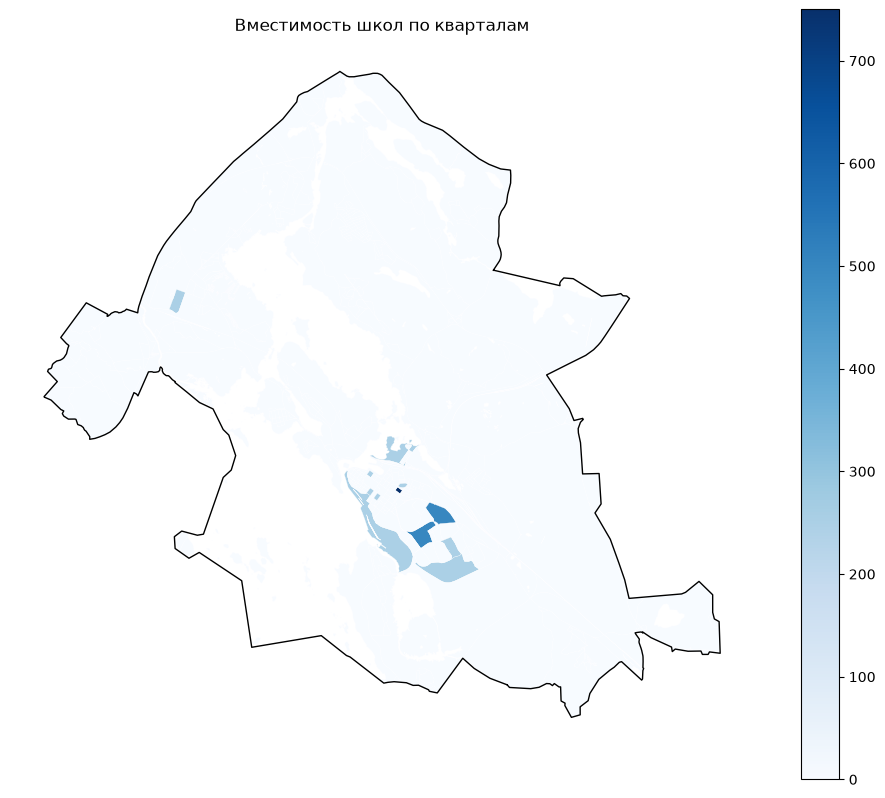

,count,capacity,capacity_osm,capacity_estimated,capacity_imputed
count,12.0,12.0,12.0,12.0,12.0
mean,1.3,333.3,0.0,333.3,1.3
std,0.7,162.8,0.0,162.8,0.7
min,1.0,250.0,0.0,250.0,1.0
25%,1.0,250.0,0.0,250.0,1.0
50%,1.0,250.0,0.0,250.0,1.0
75%,1.2,312.5,0.0,312.5,1.2
max,3.0,750.0,0.0,750.0,3.0


In [16]:
from blocksnet.preprocessing.imputing import impute_services

boundaries, boundaries_metric, metric_crs = load_boundary_and_crs()
blocks = ensure_block_index(read_geojson(PROCESSED_DIR / "blocks.geojson")).to_crs(metric_crs)

schools_path = RAW_DIR / "schools_raw.geojson"
if USE_CACHE and schools_path.exists():
    schools = read_geojson(schools_path)
    print("Школы загружены из кэша.")
else:
    schools = ox.features_from_polygon(
        boundaries.to_crs(4326).union_all(),
        tags={"amenity": "school"},
    ).reset_index(drop=True)
    if "capacity" in schools.columns:
        schools["capacity"] = pd.to_numeric(schools["capacity"], errors="coerce")
    else:
        schools["capacity"] = np.nan
    schools = schools[["geometry", "capacity"]]
    write_geojson(schools, schools_path)
    print("Школы скачаны из OSM.")

if len(schools) == 0:
    raise ValueError("В OSM не найдено школ. Проверьте территорию и теги.")

if "capacity" not in schools.columns:
    schools["capacity"] = np.nan

schools = schools.to_crs(metric_crs)
# Запоминаем, у каких школ вместимость указана в OSM. impute_services оставляет
# только capacity и геометрию, поэтому отметки добавляем после заполнения.
capacity_from_osm = schools["capacity"].notna()
schools = impute_services(schools, SCHOOL_SERVICE_TYPE)
schools["capacity_imputed"] = ~capacity_from_osm
schools["capacity_osm"] = schools["capacity"].where(capacity_from_osm, 0.0)
schools["capacity_estimated"] = schools["capacity"].where(~capacity_from_osm, 0.0)
write_geojson(schools, PROCESSED_DIR / "schools_imputed.geojson")
schools_blocks = aggregate_objects(blocks, schools.copy())[0]
schools_blocks.index.name = "block_id"
write_geojson(schools_blocks, PROCESSED_DIR / "schools_blocks.geojson")

print("Школ:", len(schools))
print("Суммарная вместимость, мест:", int(round(schools["capacity"].sum())))
print("Школ с нулевой вместимостью после импутации:", int((schools["capacity"] == 0).sum()))
print(
    "Вместимость из OSM:", int(capacity_from_osm.sum()), "школ,",
    int(round(schools["capacity_osm"].sum())), "мест",
)
print(
    "Вместимость подставлена BlocksNet:", int((~capacity_from_osm).sum()), "школ,",
    int(round(schools["capacity_estimated"].sum())), "мест",
)

fig, ax = plt.subplots(figsize=(12, 10))
schools_blocks.plot(
    "capacity",
    cmap="Blues",
    legend=True,
    ax=ax,
    edgecolor="white",
    linewidth=0.2,
    missing_kwds={"color": "lightgrey"},
)
boundaries_metric.boundary.plot(ax=ax, color="black", linewidth=1)
ax.set_title("Вместимость школ по кварталам")
ax.set_axis_off()
plt.show()

school_columns = ["count", "capacity", "capacity_osm", "capacity_estimated", "capacity_imputed"]
display(schools_blocks.loc[schools_blocks["count"] > 0, school_columns].describe().round(1))

### 8.1. Где вместимость школ оценена

Синие точки — вместимость указана в OSM. Оранжевые — тега `capacity` не было, и BlocksNet
подставил минимальный типовой размер школы (250 мест). В колонках кварталов это видно так:
`capacity_osm` — места из OSM, `capacity_estimated` — подставленные места,
`capacity_imputed` — число школ с подставленной вместимостью.

D:\ai\python-package-boilerplate-main\.venv\Lib\site-packages\geopandas\plotting.py:1408: UserWarning: The GeoSeries you are attempting to plot is empty. Nothing has been displayed.
  return plot_dataframe(data, *args, **kwargs)


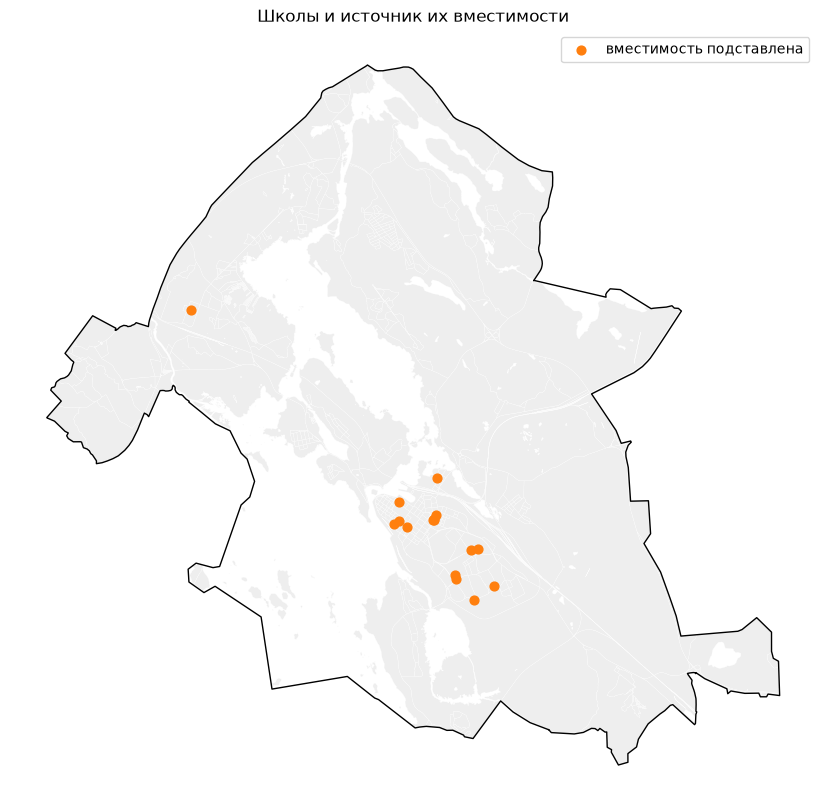

,capacity,capacity_imputed,capacity_osm,capacity_estimated
0,250.0,True,0.0,250.0
1,250.0,True,0.0,250.0
2,250.0,True,0.0,250.0
3,250.0,True,0.0,250.0
4,250.0,True,0.0,250.0
5,250.0,True,0.0,250.0
6,250.0,True,0.0,250.0
7,250.0,True,0.0,250.0
8,250.0,True,0.0,250.0
9,250.0,True,0.0,250.0


In [17]:
schools_points = read_geojson(PROCESSED_DIR / "schools_imputed.geojson").to_crs(metric_crs)
schools_points["capacity_imputed"] = schools_points["capacity_imputed"].map(
    lambda value: value.strip().lower() in {"true", "1"} if isinstance(value, str) else bool(value)
)
schools_points["geometry"] = schools_points.representative_point()

fig, ax = plt.subplots(figsize=(12, 10))
blocks.plot(ax=ax, color="#eeeeee", edgecolor="white", linewidth=0.2)
schools_points[~schools_points["capacity_imputed"]].plot(
    ax=ax, color="#1f77b4", markersize=40, label="вместимость из OSM"
)
schools_points[schools_points["capacity_imputed"]].plot(
    ax=ax, color="#ff7f0e", markersize=40, label="вместимость подставлена"
)
boundaries_metric.boundary.plot(ax=ax, color="black", linewidth=1)
ax.legend()
ax.set_title("Школы и источник их вместимости")
ax.set_axis_off()
plt.show()

display(schools_points.drop(columns="geometry").round(0))

## 9. Конкурентная обеспеченность школами

Считаем, какая доля потребности в школах покрывается с учётом конкуренции между кварталами.
`provision_strong` — обеспеченность в пределах нормативной доступности, `provision_weak` —
с учётом учреждений за её пределами.

Нормативы берём из справочника BlocksNet: для школы это 120 мест на 1000 жителей и
15 минут доступности.

2026-10-30 00:11:04.220 | INFO     | blocksnet.analysis.provision.competitive.core:_initialize_provision_df:29 - Initializing provision DataFrame
2026-10-30 00:11:04.224 | WARNING  | blocksnet.analysis.provision.competitive.core:_initialize_provision_df:33 - No demand in columns. Imputing using population column and demand parameter
2026-10-30 00:11:04.241 | INFO     | blocksnet.analysis.provision.competitive.core:_supply_self:56 - Supplying blocks with own capacities
2026-10-30 00:11:04.268 | INFO     | blocksnet.analysis.provision.competitive.core:competitive_provision:190 - Setting and solving LP problems until max depth or break condition reached
2026-10-30 00:11:05.357 | SUCCESS  | blocksnet.analysis.provision.competitive.core:competitive_provision:203 - Provision assessment finished


Норматив: мест на 1000 жителей: 120
Нормативная доступность, минут: 15
Глубина поиска школ: 1 × 15 минут
Обеспеченность strong, всего: 0.459
Обеспеченность weak, всего: 0.459


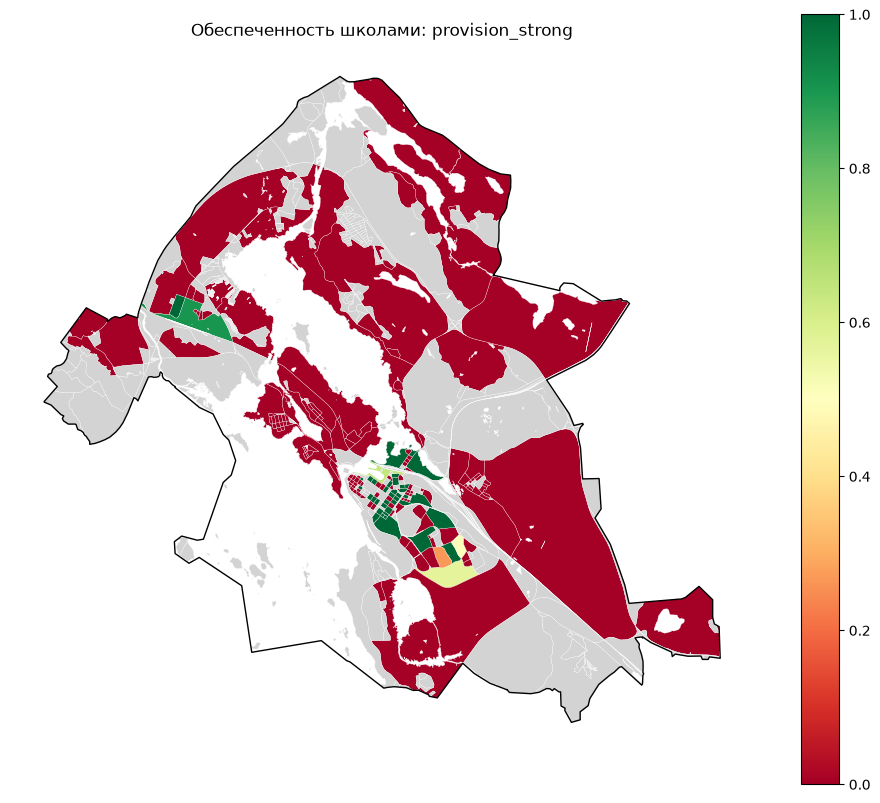

,demand,capacity,provision_strong,provision_weak
count,1143.00,1143.00,191.00,191.00
mean,7.63,3.50,0.21,0.21
std,40.31,37.56,0.40,0.40
min,0.00,0.00,0.00,0.00
25%,0.00,0.00,0.00,0.00
50%,0.00,0.00,0.00,0.00
75%,0.00,0.00,0.00,0.00
max,520.00,750.00,1.00,1.00


In [18]:
from blocksnet.analysis.provision import (
    competitive_provision,
    provision_strong_total,
    provision_weak_total,
)
from blocksnet.config import service_types_config

blocks = ensure_block_index(read_geojson(PROCESSED_DIR / "blocks.geojson")).to_crs(metric_crs)
buildings_blocks = ensure_block_index(read_geojson(PROCESSED_DIR / "buildings_blocks.geojson")).to_crs(metric_crs)
schools_blocks = ensure_block_index(read_geojson(PROCESSED_DIR / "schools_blocks.geojson")).to_crs(metric_crs)

acc_mx = pd.read_csv(RESULTS_DIR / "accessibility_matrix.csv", index_col=0)
acc_mx.index = acc_mx.index.astype(int)
acc_mx.columns = acc_mx.columns.astype(int)
acc_mx = acc_mx.reindex(index=blocks.index, columns=blocks.index)

school_config = service_types_config[SCHOOL_SERVICE_TYPE]
school_demand = int(school_config["demand"])
school_accessibility = int(school_config["accessibility"])

# Как в pipeline.ipynb: школы ищутся только в пределах норматива (1 × 15 минут).
# При таком значении provision_weak совпадает с provision_strong. Поставьте 2,
# чтобы искать школы до 30 минут: тогда provision_weak покажет дальние школы.
PROVISION_MAX_DEPTH = 1

provision_input = buildings_blocks[["population"]].join(schools_blocks[["capacity"]])
prov_df, links_df = competitive_provision(
    provision_input,
    acc_mx,
    school_accessibility,
    school_demand,
    max_depth=PROVISION_MAX_DEPTH,
)

prov_df.index = prov_df.index.astype(int)
prov_df.to_csv(RESULTS_DIR / "provision.csv", index=True)
links_df.to_csv(RESULTS_DIR / "provision_links.csv", index=True)

print("Норматив: мест на 1000 жителей:", school_demand)
print("Нормативная доступность, минут:", school_accessibility)
print("Глубина поиска школ:", PROVISION_MAX_DEPTH, "×", school_accessibility, "минут")
print("Обеспеченность strong, всего:", round(float(provision_strong_total(prov_df)), 3))
print("Обеспеченность weak, всего:", round(float(provision_weak_total(prov_df)), 3))

fig, ax = plt.subplots(figsize=(12, 10))
blocks.join(prov_df)[["geometry", "provision_strong"]].plot(
    "provision_strong",
    cmap="RdYlGn",
    vmin=0,
    vmax=1,
    legend=True,
    ax=ax,
    edgecolor="white",
    linewidth=0.2,
    missing_kwds={"color": "lightgrey", "label": "нет данных"},
)
boundaries_metric.boundary.plot(ax=ax, color="black", linewidth=1)
ax.set_title("Обеспеченность школами: provision_strong")
ax.set_axis_off()
plt.show()

display(prov_df[["demand", "capacity", "provision_strong", "provision_weak"]].describe().round(2))

### 9.1. Все результаты обеспеченности

- `provision_strong` — доля потребности, закрытая школами **в пределах 15 минут**.
- `provision_weak` — то же плюс школы дальше 15 минут. При `PROVISION_MAX_DEPTH = 1`
  дальние школы не ищутся, поэтому значения совпадают со strong.
- `demand_left` — сколько мест не хватило жителям квартала (места).
- `capacity_left` — сколько мест в школах квартала осталось свободными (места).
- Связи `source → target` — сколько детей из квартала `source` распределено в школы
  квартала `target` и сколько минут туда идти.

Все значения — модель: население и часть вместимости оценены.

,значение
"потребность, мест",8717
закрыто в пределах норматива,4000
закрыто дальше норматива,0
не хватает мест,4717
всего мест в школах,4000
свободных мест,0


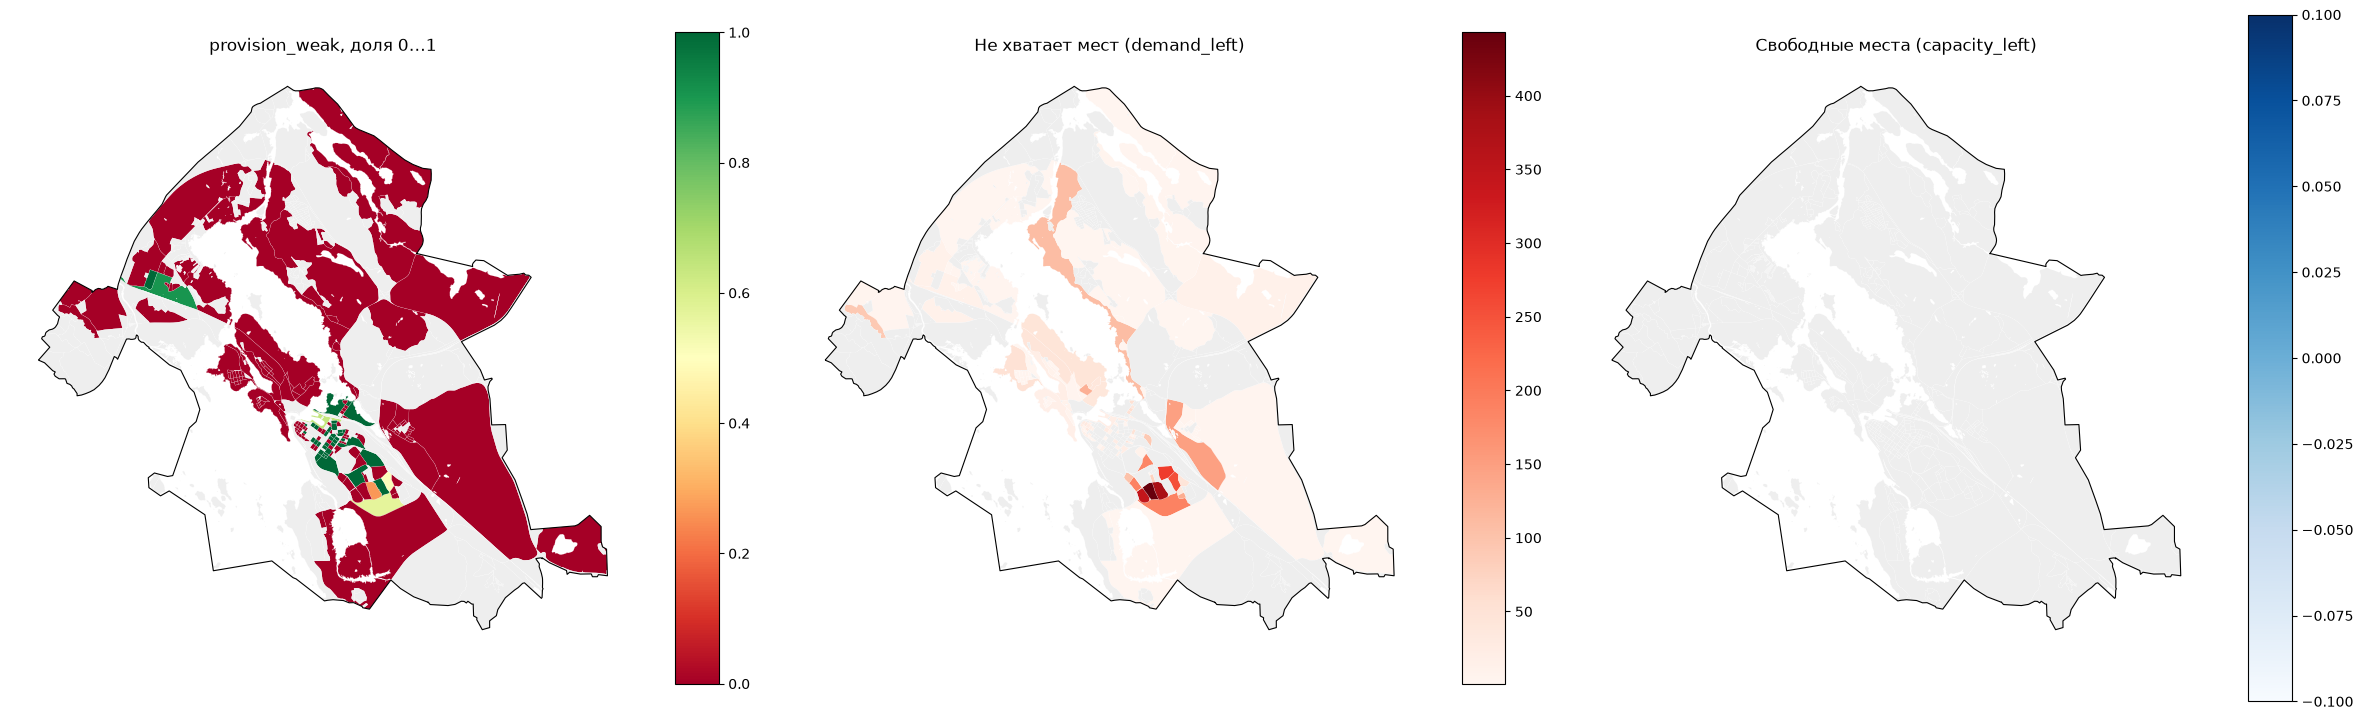

Самые крупные потоки детей между кварталами:


,source,target,value,time_min
30,324,323,224.0,5.1
24,252,36,168.0,8.0
7,101,36,149.0,3.5
33,370,250,140.0,12.1
25,259,241,138.0,5.6
6,94,93,114.0,10.0
23,211,507,100.0,4.2
1,79,36,79.0,6.1
0,75,36,78.0,2.8
20,202,36,78.0,3.4


In [19]:
prov_df = pd.read_csv(RESULTS_DIR / "provision.csv", index_col=0)
prov_df.index = prov_df.index.astype(int)
links_df = pd.read_csv(RESULTS_DIR / "provision_links.csv")

totals = pd.Series(
    {
        "потребность, мест": prov_df["demand"].sum(),
        "закрыто в пределах норматива": prov_df["demand_within"].sum(),
        "закрыто дальше норматива": prov_df["demand_without"].sum(),
        "не хватает мест": prov_df["demand_left"].sum(),
        "всего мест в школах": prov_df["capacity"].sum(),
        "свободных мест": prov_df["capacity_left"].sum(),
    }
).round(0)
display(totals.to_frame("значение"))

provision_map = blocks.join(prov_df[["provision_weak", "demand_left", "capacity_left"]])
provision_map["demand_left"] = provision_map["demand_left"].where(provision_map["demand_left"] > 0)
provision_map["capacity_left"] = provision_map["capacity_left"].where(provision_map["capacity_left"] > 0)

fig, axes = plt.subplots(1, 3, figsize=(24, 9))
provision_layers = [
    ("provision_weak", "provision_weak, доля 0…1", "RdYlGn", 0, 1),
    ("demand_left", "Не хватает мест (demand_left)", "Reds", None, None),
    ("capacity_left", "Свободные места (capacity_left)", "Blues", None, None),
]
for ax, (column, title, cmap, vmin, vmax) in zip(axes, provision_layers):
    provision_map.plot(
        column,
        cmap=cmap,
        vmin=vmin,
        vmax=vmax,
        legend=True,
        ax=ax,
        edgecolor="white",
        linewidth=0.1,
        missing_kwds={"color": "#eeeeee"},
    )
    boundaries_metric.boundary.plot(ax=ax, color="black", linewidth=0.8)
    ax.set_title(title)
    ax.set_axis_off()
plt.tight_layout()
plt.show()

if len(links_df) > 0:
    links_df["time_min"] = [acc_mx.at[s, t] for s, t in zip(links_df["source"], links_df["target"])]
    print("Самые крупные потоки детей между кварталами:")
    display(links_df.sort_values("value", ascending=False).head(15).round(1))
else:
    print("Связей между кварталами нет: все дети учатся в своём квартале или мест нет.")

## 10. Плотностные показатели

Считаем показатели из `pipeline.ipynb`:

- `fsi` — интенсивность использования территории;
- `gsi` — доля застроенной площади;
- `mxi` — доля жилой площади;
- `l` — средняя этажность;
- `osr` — доля открытых пространств;
- `share_living`, `share_non_living` — доли жилой и нежилой площади.

Значения безразмерные, кроме площадей.

Плотностные показатели посчитаны.


D:\ai\python-package-boilerplate-main\.venv\Lib\site-packages\pandas\core\nanops.py:1016: RuntimeWarning: invalid value encountered in subtract
  sqr = _ensure_numeric((avg - values) ** 2)
D:\ai\python-package-boilerplate-main\.venv\Lib\site-packages\numpy\lib\_function_base_impl.py:4653: RuntimeWarning: invalid value encountered in subtract
  diff_b_a = subtract(b, a)


,fsi,gsi,mxi,l,osr
count,1143.000,1143.000,406.000,406.000,1143.000
mean,0.101,0.044,0.224,1.618,inf
std,0.306,0.097,0.316,1.154,NaN
min,0.000,0.000,0.000,1.000,0.082
25%,0.000,0.000,0.000,1.000,26.430
50%,0.000,0.000,0.000,1.000,NaN
75%,0.036,0.034,0.447,1.712,NaN
max,3.999,0.671,0.900,10.000,inf


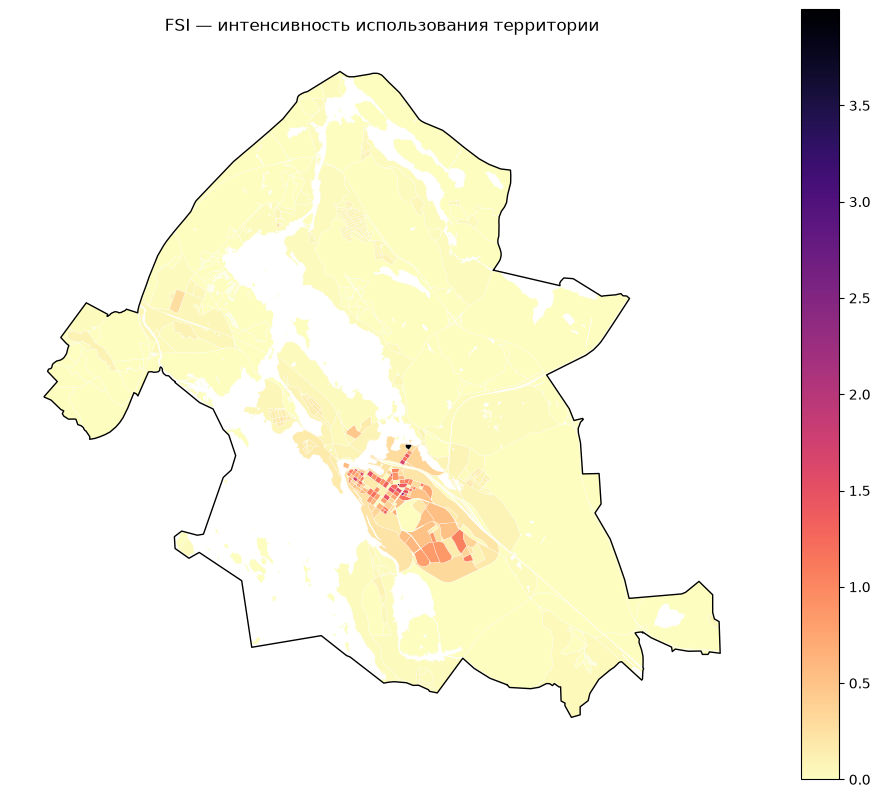

In [20]:
from blocksnet.analysis.indicators import calculate_density_indicators

blocks = ensure_block_index(read_geojson(PROCESSED_DIR / "blocks.geojson")).to_crs(metric_crs)
buildings_blocks = ensure_block_index(read_geojson(PROCESSED_DIR / "buildings_blocks.geojson")).to_crs(metric_crs)

density_df = calculate_density_indicators(buildings_blocks)
density_df.index = density_df.index.astype(int)
density_df.to_csv(RESULTS_DIR / "density.csv", index=True)

print("Плотностные показатели посчитаны.")
display(density_df[["fsi", "gsi", "mxi", "l", "osr"]].describe().round(3))

density_map = join_extra(blocks, density_df)
fig, ax = plt.subplots(figsize=(12, 10))
density_map.plot(
    "fsi",
    cmap="magma_r",
    legend=True,
    ax=ax,
    edgecolor="white",
    linewidth=0.2,
    missing_kwds={"color": "lightgrey"},
)
boundaries_metric.boundary.plot(ax=ax, color="black", linewidth=1)
ax.set_title("FSI — интенсивность использования территории")
ax.set_axis_off()
plt.show()


### 10.1. Карты плотности и сравнение кварталов

- `gsi` — какая доля земли квартала под зданиями (0…1).
- `mxi` — какая доля площади этажей жилая (0…1).
- `l` — средняя этажность, этажей.
- `osr` — сколько м² незастроенной земли приходится на 1 м² площади этажей.

У больших почти пустых кварталов `osr` огромный, поэтому шкала карт обрезана по 95-му
процентилю. В таблице ниже — кварталы с низкой, средней и высокой плотностью (`fsi`).

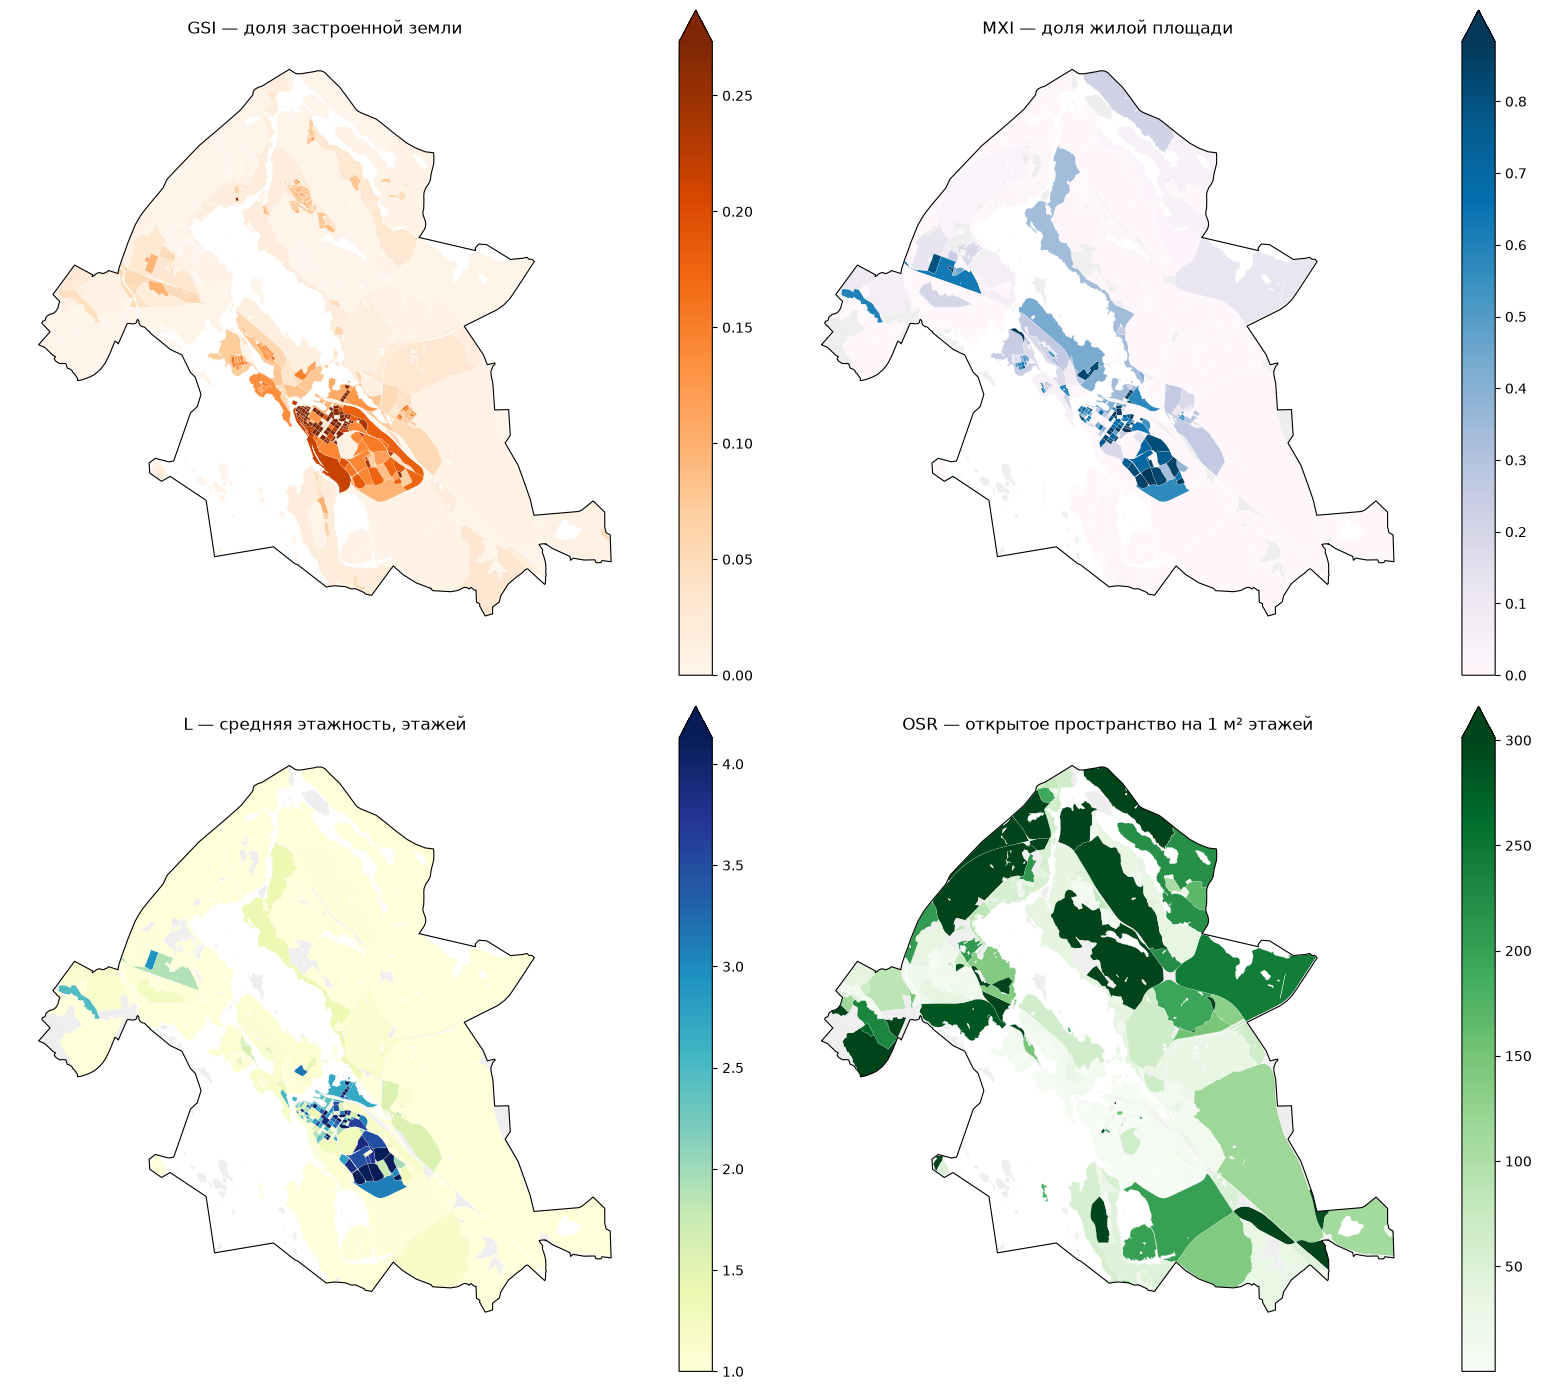

,пример,land_use,"площадь, га",fsi,gsi,mxi,l,osr
block_id,,,,,,,,
633,низкая плотность,no_data,45.89,0.01,0.01,0.00,1.00,168.31
108,средняя плотность,industrial,22.21,0.08,0.08,0.00,1.00,11.12
103,высокая плотность,residential,0.59,0.95,0.46,0.90,2.06,0.56
304,самый плотный,residential,1.53,4.00,0.67,0.22,5.96,0.08


In [21]:
density_df = pd.read_csv(RESULTS_DIR / "density.csv", index_col=0)
density_df.index = density_df.index.astype(int)
density_map = join_extra(blocks, density_df.replace([np.inf, -np.inf], np.nan))

density_layers = [
    ("gsi", "GSI — доля застроенной земли", "Oranges"),
    ("mxi", "MXI — доля жилой площади", "PuBu"),
    ("l", "L — средняя этажность, этажей", "YlGnBu"),
    ("osr", "OSR — открытое пространство на 1 м² этажей", "Greens"),
]
fig, axes = plt.subplots(2, 2, figsize=(16, 14))
for ax, (column, title, cmap) in zip(axes.flat, density_layers):
    density_map.plot(
        column,
        cmap=cmap,
        legend=True,
        ax=ax,
        edgecolor="white",
        linewidth=0.1,
        vmax=density_map[column].quantile(0.95),
        missing_kwds={"color": "#eeeeee"},
    )
    boundaries_metric.boundary.plot(ax=ax, color="black", linewidth=0.8)
    ax.set_title(title)
    ax.set_axis_off()
plt.tight_layout()
plt.show()

developed = density_map[density_map["fsi"] > 0].dropna(subset=["fsi"])
picks = {}
for label, quantile in [("низкая плотность", 0.1), ("средняя плотность", 0.5), ("высокая плотность", 0.9)]:
    target = developed["fsi"].quantile(quantile)
    picks[label] = (developed["fsi"] - target).abs().idxmin()
picks["самый плотный"] = developed["fsi"].idxmax()

comparison = developed.loc[list(picks.values()), ["land_use", "site_area", "fsi", "gsi", "mxi", "l", "osr"]].copy()
comparison.insert(0, "пример", list(picks.keys()))
comparison["site_area"] = comparison["site_area"] / 10_000
comparison = comparison.rename(columns={"site_area": "площадь, га"})
display(comparison.round(2))

## 11. Морфотипы Spacematrix

Spacematrix группирует застроенные кварталы по этажности, плотности и доле жилья.
Это статистическая типология, а не официальный классификатор.

Если застроенных кварталов мало, число кластеров автоматически уменьшается.

Кластеров Spacematrix: 11


,кварталов
morphotype_spacematrix,
low-rise low-density non-residential,256
low-rise low-density mixed-use,44
mid-rise low-density residential,37
low-rise low-density residential,36
mid-rise residential,24
mid-rise low-density non-residential,7
high-rise high-density residential,1
mid-rise high-density mixed-use,1


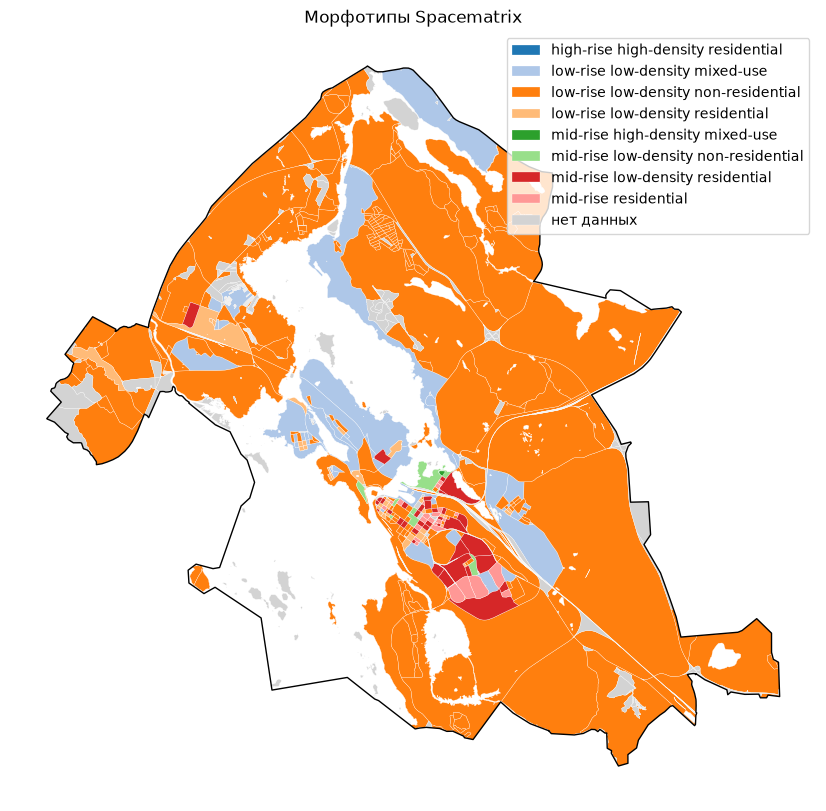

In [22]:
from blocksnet.analysis.morphotypes import get_spacematrix_morphotypes

density_df = pd.read_csv(RESULTS_DIR / "density.csv", index_col=0)
density_df.index = density_df.index.astype(int)
blocks = ensure_block_index(read_geojson(PROCESSED_DIR / "blocks.geojson")).to_crs(metric_crs)

# KMeans не принимает NaN и бесконечности. Оставляем кварталы с полными
# показателями и ненулевой плотностью застройки.
morph_input = density_df.replace([np.inf, -np.inf], np.nan)
morph_input = morph_input.dropna(subset=["l", "fsi", "mxi"])
morph_input = morph_input[morph_input["fsi"] > 0].copy()

developed_count = len(morph_input)
if developed_count < 2:
    raise ValueError(
        "Слишком мало застроенных кварталов с полными показателями для Spacematrix. "
        f"Их {developed_count}."
    )

n_clusters = min(11, developed_count)
spacematrix_df, spacematrix_clusters = get_spacematrix_morphotypes(
    morph_input,
    n_clusters=n_clusters,
)
spacematrix_df = spacematrix_df.rename(columns={"morphotype": "morphotype_spacematrix"})
spacematrix_df.index = spacematrix_df.index.astype(int)
spacematrix_df.to_csv(RESULTS_DIR / "morphotypes_spacematrix.csv", index=True)
spacematrix_clusters.to_csv(RESULTS_DIR / "spacematrix_clusters.csv", index=True)

print("Кластеров Spacematrix:", n_clusters)
display(spacematrix_df["morphotype_spacematrix"].value_counts().to_frame("кварталов"))

fig, ax = plt.subplots(figsize=(12, 10))
blocks.join(spacematrix_df)[["geometry", "morphotype_spacematrix"]].plot(
    "morphotype_spacematrix",
    cmap="tab20",
    legend=True,
    ax=ax,
    edgecolor="white",
    linewidth=0.2,
    missing_kwds={"color": "lightgrey", "label": "нет данных"},
)
boundaries_metric.boundary.plot(ax=ax, color="black", linewidth=1)
ax.set_title("Морфотипы Spacematrix")
ax.set_axis_off()
plt.show()


### 11.1. Характеристики групп Spacematrix

Для каждой группы — медианные `l`, `fsi`, `mxi`, расшифровка и число кварталов.
На диаграмме Spacematrix по горизонтали `gsi`, по вертикали `fsi`: каждая точка —
застроенный квартал, цвет — его группа.

,l,fsi,mxi,l_interpretation,fsi_interpretation,mxi_interpretation,morphotype,кварталов
cluster,,,,,,,,
0,1.08,0.08,0.29,low-rise,low-density,mixed-use,low-rise low-density mixed-use,44
1,3.17,0.50,0.72,mid-rise,low-density,residential,mid-rise low-density residential,15
2,1.00,0.05,0.00,low-rise,low-density,non-residential,low-rise low-density non-residential,237
3,4.16,1.47,0.78,mid-rise,NaN,residential,mid-rise residential,15
4,1.54,0.24,0.63,low-rise,low-density,residential,low-rise low-density residential,36
5,5.96,4.00,0.22,mid-rise,high-density,mixed-use,mid-rise high-density mixed-use,1
6,3.00,0.25,0.00,mid-rise,low-density,non-residential,mid-rise low-density non-residential,7
7,2.22,0.72,0.00,low-rise,low-density,non-residential,low-rise low-density non-residential,19
8,5.34,1.07,0.89,mid-rise,NaN,residential,mid-rise residential,9


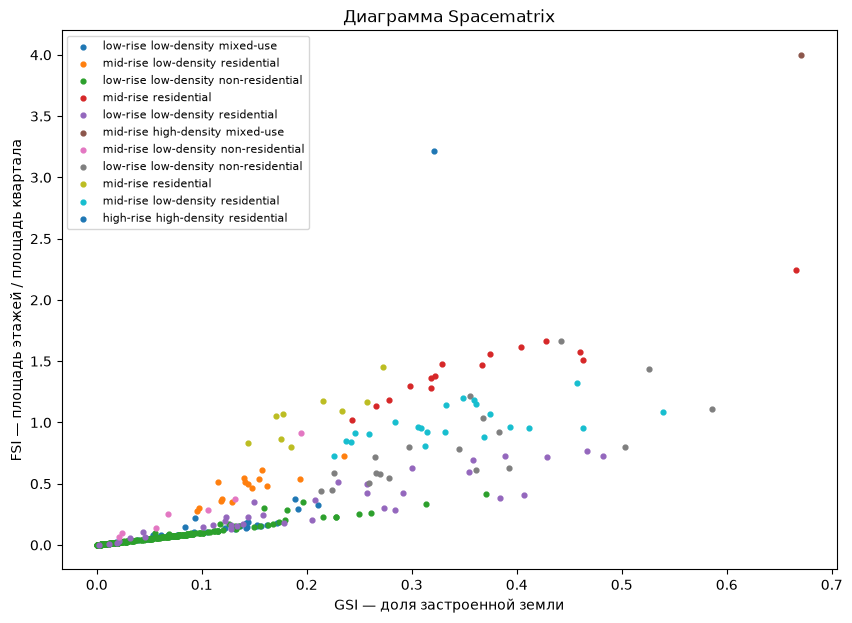

In [23]:
spacematrix_clusters = pd.read_csv(RESULTS_DIR / "spacematrix_clusters.csv", index_col=0)
cluster_sizes = spacematrix_df["cluster"].dropna().astype(int).value_counts().rename("кварталов")
spacematrix_clusters.index = spacematrix_clusters.index.astype(int)
display(spacematrix_clusters.join(cluster_sizes).round(2))

scatter = spacematrix_df.dropna(subset=["cluster"]).join(density_df[["gsi"]], rsuffix="_density")
fig, ax = plt.subplots(figsize=(10, 7))
for cluster_id, group in scatter.groupby("cluster"):
    ax.scatter(group["gsi"], group["fsi"], s=12, label=group["morphotype_spacematrix"].iloc[0])
ax.set_xlabel("GSI — доля застроенной земли")
ax.set_ylabel("FSI — площадь этажей / площадь квартала")
ax.set_title("Диаграмма Spacematrix")
ax.legend(fontsize=8, loc="upper left")
plt.show()

## 12. Морфотипы Strelka

Strelka даёт более «городскую» типологию застройки: малоэтажная, среднеэтажная,
микрорайонная, центральная и т.п. Считаем её по тем же плотностным показателям.

Морфотипы Strelka посчитаны.


,кварталов
morphotype_strelka,
low-rise non-residential,232
low-rise model,110
individual residential,41
mid-rise,18
central model,2
high-rise modern microdistrict,1
mid-rise non-residential,1
mid-rise block,1


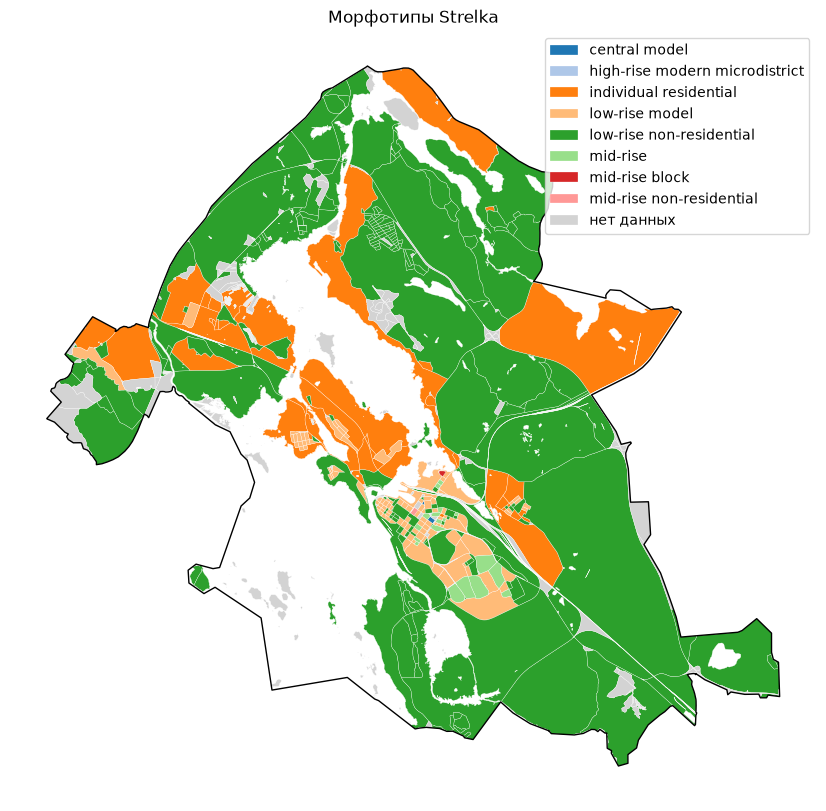

In [24]:
from blocksnet.analysis.morphotypes import get_strelka_morphotypes

strelka_input = density_df.replace([np.inf, -np.inf], np.nan)
strelka_input = strelka_input.dropna(subset=["l", "fsi", "mxi"])
strelka_input = strelka_input[strelka_input["fsi"] > 0].copy()

strelka_df = get_strelka_morphotypes(strelka_input)
strelka_df = strelka_df.rename(columns={"morphotype": "morphotype_strelka"})
strelka_df.index = strelka_df.index.astype(int)
strelka_df.to_csv(RESULTS_DIR / "morphotypes_strelka.csv", index=True)

print("Морфотипы Strelka посчитаны.")
display(strelka_df["morphotype_strelka"].value_counts().to_frame("кварталов"))

fig, ax = plt.subplots(figsize=(12, 10))
blocks.join(strelka_df)[["geometry", "morphotype_strelka"]].plot(
    "morphotype_strelka",
    cmap="tab20",
    legend=True,
    ax=ax,
    edgecolor="white",
    linewidth=0.2,
    missing_kwds={"color": "lightgrey", "label": "нет данных"},
)
boundaries_metric.boundary.plot(ax=ax, color="black", linewidth=1)
ax.set_title("Морфотипы Strelka")
ax.set_axis_off()
plt.show()


### 12.1. Чем отличаются Spacematrix и Strelka

- **Spacematrix** — статистика: KMeans сам делит кварталы этого города на группы похожих,
  а названия групп выводятся из их медиан. Группы зависят от данных конкретного города.
- **Strelka** — фиксированные правила с порогами этажности (`l` 4 и 9 этажей), плотности
  и доли жилья. Одинаковые кварталы в разных городах получат одинаковый тип.

Таблица показывает, сколько кварталов каждого типа Strelka попало в каждую группу Spacematrix.

In [25]:
morphotypes_compare = pd.read_csv(RESULTS_DIR / "morphotypes_spacematrix.csv", index_col=0)[
    ["morphotype_spacematrix"]
].join(pd.read_csv(RESULTS_DIR / "morphotypes_strelka.csv", index_col=0)[["morphotype_strelka"]])
display(pd.crosstab(morphotypes_compare["morphotype_strelka"], morphotypes_compare["morphotype_spacematrix"]))

morphotype_spacematrix,high-rise high-density residential,low-rise low-density mixed-use,low-rise low-density non-residential,low-rise low-density residential,mid-rise high-density mixed-use,mid-rise low-density non-residential,mid-rise low-density residential,mid-rise residential
morphotype_strelka,,,,,,,,
central model,0,0,0,0,0,0,0,2
high-rise modern microdistrict,1,0,0,0,0,0,0,0
individual residential,0,24,11,6,0,0,0,0
low-rise model,0,20,17,30,0,2,36,5
low-rise non-residential,0,0,228,0,0,4,0,0
mid-rise,0,0,0,0,0,0,1,17
mid-rise block,0,0,0,0,1,0,0,0
mid-rise non-residential,0,0,0,0,0,1,0,0


## 13. Area accessibility

Показывает среднее время из квартала до всех остальных кварталов с учётом их площади.
Чем меньше значение, тем лучше доступность. Это не то же самое, что среднее по матрице:
крупные кварталы влияют сильнее.

Area accessibility посчитана.
Кварталов без значения (нет маршрута хотя бы до одного квартала): 0


,area_accessibility
count,1143.00
mean,121.16
std,26.48
min,85.09
25%,97.75
50%,120.99
75%,135.17
max,236.58


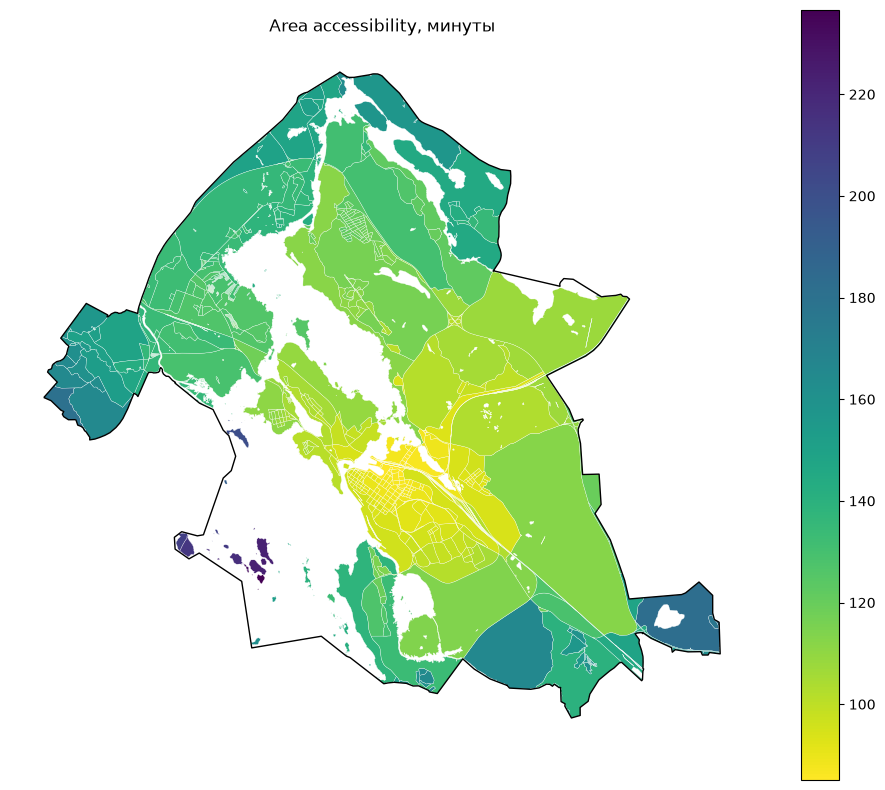

In [26]:
from blocksnet.analysis.network.accessibility import area_accessibility

blocks = ensure_block_index(read_geojson(PROCESSED_DIR / "blocks.geojson")).to_crs(metric_crs)
buildings_blocks = ensure_block_index(read_geojson(PROCESSED_DIR / "buildings_blocks.geojson")).to_crs(metric_crs)

acc_mx = pd.read_csv(RESULTS_DIR / "accessibility_matrix.csv", index_col=0)
acc_mx.index = acc_mx.index.astype(int)
acc_mx.columns = acc_mx.columns.astype(int)
acc_mx = acc_mx.reindex(index=blocks.index, columns=blocks.index)

area_acc = area_accessibility(acc_mx, buildings_blocks)
area_acc.index = area_acc.index.astype(int)
area_acc.to_csv(RESULTS_DIR / "area_accessibility.csv", index=True)

print("Area accessibility посчитана.")
print(
    "Кварталов без значения (нет маршрута хотя бы до одного квартала):",
    int(np.isinf(area_acc["area_accessibility"]).sum()),
)
area_acc_finite = area_acc.replace([np.inf, -np.inf], np.nan)
display(area_acc_finite.describe().round(2))

fig, ax = plt.subplots(figsize=(12, 10))
blocks.join(area_acc_finite)[["geometry", "area_accessibility"]].plot(
    "area_accessibility",
    cmap="viridis_r",
    legend=True,
    ax=ax,
    edgecolor="white",
    linewidth=0.2,
    missing_kwds={"color": "lightgrey"},
)
boundaries_metric.boundary.plot(ax=ax, color="black", linewidth=1)
ax.set_title("Area accessibility, минуты")
ax.set_axis_off()
plt.show()

## 14. Итоговый GeoJSON

Собираем все показатели в один слой `results/blocks_results.geojson`. Именно его потом
прочитает будущий HTML-дашборд. Одинаковые колонки не дублируются, `inf` заменяется на
пропуски.

In [27]:
blocks = ensure_block_index(read_geojson(PROCESSED_DIR / "blocks.geojson")).to_crs(metric_crs)
buildings_blocks = ensure_block_index(read_geojson(PROCESSED_DIR / "buildings_blocks.geojson")).to_crs(metric_crs)
schools_blocks = ensure_block_index(read_geojson(PROCESSED_DIR / "schools_blocks.geojson")).to_crs(metric_crs)

prov_df = pd.read_csv(RESULTS_DIR / "provision.csv", index_col=0)
prov_df.index = prov_df.index.astype(int)
density_df = pd.read_csv(RESULTS_DIR / "density.csv", index_col=0)
density_df.index = density_df.index.astype(int)
spacematrix_df = pd.read_csv(RESULTS_DIR / "morphotypes_spacematrix.csv", index_col=0)
spacematrix_df.index = spacematrix_df.index.astype(int)
strelka_df = pd.read_csv(RESULTS_DIR / "morphotypes_strelka.csv", index_col=0)
strelka_df.index = strelka_df.index.astype(int)
area_acc = pd.read_csv(RESULTS_DIR / "area_accessibility.csv", index_col=0)
area_acc.index = area_acc.index.astype(int)
median_time_by_block = pd.read_csv(RESULTS_DIR / "median_time_min.csv", index_col=0)
median_time_by_block.index = median_time_by_block.index.astype(int)

results = blocks.copy()
results = join_extra(results, buildings_blocks.drop(columns="geometry"))
results = join_extra(results, schools_blocks.drop(columns="geometry"))
results = join_extra(results, prov_df)
results = join_extra(results, density_df)
results = join_extra(results, spacematrix_df)
results = join_extra(results, strelka_df)
results = join_extra(results, area_acc)
results = join_extra(results, median_time_by_block)

for column in ["land_use", "morphotype_spacematrix", "morphotype_strelka"]:
    if column in results.columns:
        results[column] = results[column].fillna("no_data")

results.index.name = "block_id"
write_geojson(results, RESULTS_DIR / "blocks_results.geojson")

print("Строк в итоговом слое:", len(results))
print("Колонки:")
print(", ".join(map(str, results.columns)))
display(results.drop(columns="geometry").head())


Сохранено: D:\ai\python-package-boilerplate-main\python-package-boilerplate-main\examples\data\vyborg\results\blocks_results.geojson
Строк в итоговом слое: 1143
Колонки:
residential, business, recreation, industrial, transport, special, agriculture, land_use, share, site_area, geometry, is_living, number_of_floors, footprint_area, build_floor_area, living_area, non_living_area, population, floors_from_osm, count, capacity, capacity_imputed, capacity_osm, capacity_estimated, demand, demand_left, demand_within, demand_without, capacity_left, capacity_within, capacity_without, provision_strong, provision_weak, fsi, gsi, mxi, l, osr, share_living, share_non_living, cluster, morphotype_spacematrix, morphotype_strelka, area_accessibility, median_time_min


,residential,business,recreation,industrial,transport,special,agriculture,land_use,share,site_area,is_living,number_of_floors,footprint_area,build_floor_area,living_area,non_living_area,population,floors_from_osm,count,capacity,capacity_imputed,capacity_osm,capacity_estimated,demand,demand_left,demand_within,demand_without,capacity_left,capacity_within,capacity_without,provision_strong,provision_weak,fsi,gsi,mxi,l,osr,share_living,share_non_living,cluster,morphotype_spacematrix,morphotype_strelka,area_accessibility,median_time_min
block_id,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
1,0.000000,0.0,0.394742,0.000000,0.0,0.0,0.0,recreation,0.394742,4.719343e+03,0.0,0.0,0.000000,0.000000,0.000000,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0,0,0,0,0,0,0,NaN,NaN,0.000000,0.000000,NaN,NaN,inf,NaN,NaN,NaN,no_data,no_data,93.357699,80.020400
2,0.000000,0.0,0.442623,0.000000,0.0,0.0,0.0,recreation,0.442623,6.916406e+03,0.0,0.0,0.000000,0.000000,0.000000,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0,0,0,0,0,0,0,NaN,NaN,0.000000,0.000000,NaN,NaN,inf,NaN,NaN,NaN,no_data,no_data,93.637544,80.300280
3,0.092269,0.0,0.022468,0.000000,0.0,0.0,0.0,residential,0.092269,6.066114e+04,3.0,9.0,2796.959574,4053.442900,2382.391525,1671.051375,79.0,2.0,7.0,0.0,0.0,0.0,0.0,10,10,0,0,0,0,0,0.0,0.0,0.066821,0.046108,0.587745,1.449232,14.275317,0.851779,0.597453,4.0,low-rise low-density residential,individual residential,97.651484,74.979000
4,0.323237,0.0,0.000000,0.062903,0.0,0.0,0.0,residential,0.323237,3.319066e+05,17.0,113.0,25680.586356,28093.596555,5001.891204,23091.705351,159.0,35.0,100.0,0.0,0.0,0.0,0.0,20,20,0,0,0,0,0,0.0,0.0,0.084643,0.077373,0.178044,1.093962,10.900208,0.194773,0.899189,0.0,low-rise low-density mixed-use,individual residential,102.799689,71.487785
5,0.028745,0.0,0.000000,0.000000,0.0,0.0,0.0,residential,0.028745,2.526096e+06,1.0,325.0,22399.456578,22399.456578,76.002126,22323.454452,2.0,1.0,325.0,0.0,0.0,0.0,0.0,1,1,0,0,0,0,0,0.0,0.0,0.008867,0.008867,0.003393,1.000000,111.774871,0.003393,0.996607,2.0,low-rise low-density non-residential,low-rise non-residential,182.465468,190.828780


## 15. Сводка и проверки

Сохраняем короткую таблицу `summary.csv` и текстовый отчёт `validation_report.txt`.
Проверки не заменяют визуальный контроль, но помогают заметить грубые ошибки.

In [28]:
blocks = ensure_block_index(read_geojson(PROCESSED_DIR / "blocks.geojson")).to_crs(metric_crs)
buildings_blocks = ensure_block_index(read_geojson(PROCESSED_DIR / "buildings_blocks.geojson")).to_crs(metric_crs)
schools_blocks = ensure_block_index(read_geojson(PROCESSED_DIR / "schools_blocks.geojson")).to_crs(metric_crs)
results = read_geojson(RESULTS_DIR / "blocks_results.geojson")

acc_mx = pd.read_csv(RESULTS_DIR / "accessibility_matrix.csv", index_col=0)
acc_mx.index = acc_mx.index.astype(int)
acc_mx.columns = acc_mx.columns.astype(int)
acc_mx = acc_mx.reindex(index=blocks.index, columns=blocks.index)
prov_df = pd.read_csv(RESULTS_DIR / "provision.csv", index_col=0)
prov_df.index = prov_df.index.astype(int)

finite_values = acc_mx.values[np.isfinite(acc_mx.values)]
summary_rows = [
    ("territory", TERRITORY_LABEL),
    ("territory_osm_id", TERRITORY_OSM_ID),
    ("data_source", "OpenStreetMap / Overpass API"),
    ("graph_source", "OpenStreetMap pedestrian network"),
    ("graph_type", GRAPH_TYPE),
    ("walk_speed_kmh", WALK_SPEED_KMH),
    ("blocksnet_version", md.version("blocksnet")),
    ("blocks_count", len(blocks)),
    ("buildings_count", len(read_geojson(RAW_DIR / "buildings_raw.geojson"))),
    ("schools_count", len(read_geojson(RAW_DIR / "schools_raw.geojson"))),
    ("population_total", round(float(buildings_blocks["population"].sum()), 1)),
    ("school_capacity_total", round(float(schools_blocks["capacity"].sum()), 1)),
    ("school_capacity_from_osm", round(float(schools_blocks["capacity_osm"].sum()), 1)),
    ("school_capacity_estimated", round(float(schools_blocks["capacity_estimated"].sum()), 1)),
    ("schools_with_estimated_capacity", int(schools_blocks["capacity_imputed"].sum())),
    (
        "buildings_with_osm_floors_share",
        round(float(buildings_blocks["floors_from_osm"].sum() / buildings_blocks["count"].sum()), 4),
    ),
    ("median_travel_time_min", round(float(np.median(finite_values)), 2)),
    ("share_unreachable_pairs", round(float(np.isinf(acc_mx.values).mean()), 4)),
    ("provision_strong_mean", round(float(np.nanmean(prov_df["provision_strong"])), 4)),
    ("provision_weak_mean", round(float(np.nanmean(prov_df["provision_weak"])), 4)),
    ("area_accessibility_median_min", round(float(results["area_accessibility"].median()), 2)),
]

summary = pd.DataFrame(summary_rows, columns=["metric", "value"])
summary.to_csv(RESULTS_DIR / "summary.csv", index=False)
print("Сводка сохранена.")
display(summary)

Сводка сохранена.


,metric,value
0,territory,Выборг
1,territory_osm_id,1572051
2,data_source,OpenStreetMap / Overpass API
3,graph_source,OpenStreetMap pedestrian network
4,graph_type,walk
5,walk_speed_kmh,5.0
6,blocksnet_version,1.0.0a9
7,blocks_count,1143
8,buildings_count,14536
9,schools_count,16


In [29]:
checks = []


def check(name, condition, details=""):
    checks.append((name, bool(condition), details))
    print(("OK  " if condition else "FAIL"), name, details)


check("Кварталы есть", len(blocks) > 0, f"{len(blocks)} шт.")
check("Здания есть", len(read_geojson(RAW_DIR / "buildings_raw.geojson")) > 0)
check("Школы есть", len(read_geojson(RAW_DIR / "schools_raw.geojson")) > 0)
check(
    "Размер матрицы совпадает с числом кварталов",
    acc_mx.shape == (len(blocks), len(blocks)),
    f"{acc_mx.shape}",
)
check("В матрице есть конечные значения", int(np.isfinite(acc_mx.values).sum()) > 0)
check(
    "Координаты итогового слоя заданы",
    results.crs is not None,
    str(results.crs),
)
check(
    "Число строк итогового слоя совпадает с числом кварталов",
    len(results) == len(blocks),
    f"{len(results)} / {len(blocks)}",
)

required_columns = [
    "land_use",
    "population",
    "capacity",
    "provision_strong",
    "provision_weak",
    "fsi",
    "gsi",
    "mxi",
    "l",
    "osr",
    "morphotype_spacematrix",
    "morphotype_strelka",
    "area_accessibility",
]
missing_columns = [column for column in required_columns if column not in results.columns]
check("Все основные колонки есть", not missing_columns, f"нет: {missing_columns}")

numeric_results = results.select_dtypes(include=[np.number])
check(
    "В итоговом слое нет бесконечностей",
    int(np.isinf(numeric_results).sum().sum()) == 0,
)

land_use_share_columns = [
    "residential", "business", "recreation", "industrial", "transport", "special", "agriculture",
]
max_land_use_share = float(results[land_use_share_columns].max().max())
check(
    "Доли land use не больше 1",
    max_land_use_share <= 1 + 1e-6,
    f"максимум {max_land_use_share:.3f}",
)

provision_values = prov_df["provision_strong"].dropna()
check(
    "provision_strong в диапазоне 0…1",
    len(provision_values) > 0
    and float(provision_values.min()) >= -1e-6
    and float(provision_values.max()) <= 1 + 1e-6,
    f"{float(provision_values.min()):.3f}…{float(provision_values.max()):.3f}",
)

report_lines = ["Отчёт проверки учебного исследования Выборга", ""]
for name, status, details in checks:
    report_lines.append(f"[{'OK' if status else 'FAIL'}] {name} {details}")
report_lines.append("")
report_lines.append(f"Кварталов: {len(blocks)}")
report_lines.append(f"Зданий: {len(read_geojson(RAW_DIR / 'buildings_raw.geojson'))}")
report_lines.append(f"Школ: {len(read_geojson(RAW_DIR / 'schools_raw.geojson'))}")
report_lines.append(f"Медианное время, минут: {float(np.median(finite_values)):.2f}")
report_lines.append(f"Доля пар без маршрута: {float(np.isinf(acc_mx.values).mean()) * 100:.2f}%")

report_path = RESULTS_DIR / "validation_report.txt"
report_path.write_text("\n".join(report_lines), encoding="utf-8")
print("Отчёт сохранён:", report_path)

failed = [name for name, status, _ in checks if not status]
if failed:
    raise AssertionError("Не прошли проверки: " + ", ".join(failed))


OK   Кварталы есть 1143 шт.
OK   Здания есть 
OK   Школы есть 
OK   Размер матрицы совпадает с числом кварталов (1143, 1143)
OK   В матрице есть конечные значения 
OK   Координаты итогового слоя заданы EPSG:4326
OK   Число строк итогового слоя совпадает с числом кварталов 1143 / 1143
OK   Все основные колонки есть нет: []
OK   В итоговом слое нет бесконечностей 
OK   Доли land use не больше 1 максимум 1.000
OK   provision_strong в диапазоне 0…1 0.000…1.000
Отчёт сохранён: D:\ai\python-package-boilerplate-main\python-package-boilerplate-main\examples\data\vyborg\results\validation_report.txt


## 16. Как читать результаты

- Сравните кварталы с низкой `provision_strong` и низкой `area_accessibility`: где школа
  далеко или мест не хватает?
- Посмотрите, какие морфотипы преобладают в центре и на окраинах.
- Сопоставьте `land_use` с плотностью и населением.
- Помните об ограничениях: OSM неполный, население и вместимость школ — оценки,
  пешеходная скорость усреднена, граф не учитывает закрытые территории.

## 17. Повторный запуск

**Первая установка (один раз).** Откройте PowerShell и выполните:

```powershell
cd "D:\ai\python-package-boilerplate-main\python-package-boilerplate-main"
& "D:\ai\python-package-boilerplate-main\.venv\Scripts\Activate.ps1"
python -m pip install --upgrade pip
python -m pip install "blocksnet[ipynb,torch]==1.0.0a9" "osmnx>=2.0,<3.0" jupyterlab
jupyter lab
```

Зависимости также записаны в `pyproject.toml`, чтобы версии не потерялись.

Если PowerShell не разрешает активацию окружения, выполните один раз:

```powershell
Set-ExecutionPolicy -Scope CurrentUser RemoteSigned
```

В первой ячейке ноутбука должно быть напечатано `blocksnet: 1.0.0a9`. Если версия другая,
значит установка не применилась: проверьте, что Jupyter запущен из того же окружения `.venv`.

**Обычный повторный запуск без скачивания:**

1. Оставьте `USE_CACHE = True`.
2. Запустите ячейки сверху вниз.
3. Граница, OSM-слои, граф и матрица прочитаются с диска.

**Только пересчёт показателей:**

1. Поменяйте `RUN_CALCULATIONS = True`.
2. Запустите ячейки начиная с раздела 9 (или с нужного показателя).

**Если меняли территорию или тип графа:** сначала удалите `raw` и `cache`, потом
запустите ноутбук сверху вниз.

**Принудительно обновить OSM-данные:**

```powershell
Remove-Item -Recurse -Force "examples\data\vyborg\raw"
```

**Обновить граф и матрицу:**

```powershell
Remove-Item -Force "examples\data\vyborg\cache\walk_graph.pickle"
Remove-Item -Force "examples\data\vyborg\results\accessibility_matrix.csv"
```

**Полностью очистить результаты:**

```powershell
Remove-Item -Recurse -Force "examples\data\vyborg\processed"
Remove-Item -Recurse -Force "examples\data\vyborg\results"
```

После удаления запустите ноутбук сверху вниз. Папки создадутся автоматически.

## 18. Дашборд

Страницу собирает отдельный файл `examples/build_dashboard.py`. Он только читает готовые
GeoJSON и CSV из `examples/data/vyborg` и ничего не скачивает и не пересчитывает.

**Порядок после любых изменений в данных или коде:**

1. В Jupyter: **Kernel → Restart Kernel and Run All Cells**. При `USE_CACHE = True` и
   `RUN_CALCULATIONS = True` граница, слои OSM, граф и матрица читаются с диска.
2. Проверьте, что в разделе 15 все проверки `OK`, и сохраните ноутбук (**Ctrl + S**).
3. В PowerShell из папки проекта соберите страницу:

```powershell
cd "D:\ai\python-package-boilerplate-main\python-package-boilerplate-main"
& "D:\ai\python-package-boilerplate-main\.venv\Scripts\python.exe" examples\build_dashboard.py
```

4. Откройте `examples\dashboard.html` в браузере. Для подложки карты и библиотек Leaflet и
   Chart.js нужен интернет.

На странице: интерактивная карта со всеми показателями, графики, таблицы (в том числе
фрагмент матрицы доступности, школы, потоки детей, группы Spacematrix), выводы, словарь
показателей, источники и ограничения.

## Краткие выводы

По запуску 29.10.2026 (OSM на эту дату, пешеходный граф 5 км/ч, BlocksNet 1.0.0a9).
Цифры — модель на открытых данных, а не официальная статистика.

1. **Территория.** Город Выборг (OSM relation 1572051), 160,8 км². Нарезано 1143 квартала
   на 123 км², остальное — вода. Медианный квартал — 0,45 га, но на окраинах есть лесные
   кварталы в сотни гектаров.
2. **Население.** По площади 14 536 зданий из OSM оценено около 71,8 тыс. жителей.
   Самые населённые кварталы — 370 и 324 (примерно по 4,3 тыс. человек).
3. **Школы.** В OSM 16 школ, и ни у одной нет вместимости: каждой подставлено 250 мест,
   всего 4000. По нормативу 120 мест на 1000 жителей нужно 8717 мест. В пределах 15 минут
   пешком закрыто 46 % потребности. 149 из 191 жилого квартала (около 31,5 тыс. жителей)
   не получили места рядом. **Главная причина дефицита — заниженная вместимость**, реальные
   школы больше; вывод о нехватке требует проверки по реальным данным.
4. **Застройка.** Этажность указана в OSM только у 13 % зданий, остальные считаются
   одноэтажными. Поэтому 94 % застроенных кварталов попали в малоэтажные морфотипы
   Strelka, и только у 36 кварталов FSI больше 1. Реальная многоэтажная застройка
   (советские микрорайоны) в модели недооценена.
5. **Доступность.** Медианное время пешком между двумя кварталами — 106 минут: в границы
   города входят большие леса и заливы. Area accessibility — от 85 до 237 минут, лучшая
   в центральных кварталах.
6. **Функциональное использование.** У 806 из 1143 кварталов нет данных `landuse` в OSM,
   ещё у 89 кварталов преобладающая функция занимает меньше 20 % площади. Карту `land_use`
   стоит читать вместе с картой `share`.
7. **Обеспеченность weak** совпадает со strong: как в `pipeline.ipynb`, школы дальше
   15 минут не рассматривались (`PROVISION_MAX_DEPTH = 1`).

**Что улучшит результат:** реальная вместимость школ, этажность зданий (например, из
реестра жилого фонда) и функциональные зоны из генплана вместо OSM.

## План работы

Работа шла по практике 2 курса «Технологии искусственного интеллекта в урбанистике»
по схеме Plan → Build: агент пишет код в ноутбуке, ячейки запускаются вручную.

| Этап | Результат | Статус |
|---|---|---|
| 1. Установка BlocksNet 1.0.0a9 с `torch` в `.venv` | версии в первой ячейке | готово |
| 2. Граница Выборга, дороги, ж/д, вода из OSM | `raw/*.geojson`, разделы 1–2 | готово |
| 3. Нарезка кварталов и land use | `processed/blocks.geojson`, разделы 3–4 | готово |
| 4. Остановка STOP и справочник метрик | справочник перед STOP | готово |
| 5. Пешеходный граф и матрица времени | `cache/walk_graph.pickle`, `results/accessibility_matrix.csv` | готово |
| 6. Здания, население, школы | `processed/buildings_blocks.geojson`, `schools_blocks.geojson` | готово |
| 7. Обеспеченность, плотность, морфотипы, area accessibility | `results/*.csv`, разделы 9–13 | готово |
| 8. Итоговый слой, сводка, проверки | `results/blocks_results.geojson`, `summary.csv`, `validation_report.txt` | готово |
| 9. Дашборд | `examples/build_dashboard.py` → `examples/dashboard.html` | готово |
| 10. Сверка с `pipeline.ipynb` и исправления | двойной учёт зон land use, выводы дашборда | готово |
| 11. Публикация в GitHub | репозиторий `urban-ai-practice` | осталось |

## Основные запросы к ИИ-агенту

Запросы взяты из гайда практики 2, территория и система подставлены.

1. **План (режим Plan).** «Помоги спланировать учебное исследование территории Выборг,
   Ленинградская область, Россия с помощью BlocksNet. Я работаю в Windows… Изучи текущий
   учебный проект и примеры подготовки данных в https://github.com/aimclub/blocksnet,
   особенно examples/pipeline.ipynb… Отметь в ноутбуке остановку после подготовки
   кварталов… Сейчас только составь план, выполнение начнём в Build.»
2. **Выполнение (Build).** «Хорошо, делай эти изменения, поставив задачи.»
3. **Метрики на остановке.** «Какие метрики есть в BlocksNet? Объясни простыми словами и
   отдельно перечисли все показатели из pipeline.ipynb. Что они означают, в каких единицах
   измеряются и что помогут узнать о нашем городе? Сохрани объяснение в ноутбуке. Пока не
   запускай расчёты.»
4. **Полнота расчётов.** «Проверь, что в ноутбуке есть код расчёта и отображения всех
   показателей из примера. Допиши недостающие ячейки и пояснения, но не запускай их.
   Покажи, какие ячейки мне выполнить дальше.»
5. **Дашборд.** «Расчёты выполнены, результаты сохранены. Создай отдельный Python-файл,
   который читает готовые GeoJSON и собирает один dashboard.html с интерактивной картой,
   графиками, таблицами всех показателей и выводами…»
6. **Сверка.** «Сверь сохранённые результаты с pipeline.ipynb. Покажи таблицу: показатель —
   где он в ноутбуке — где он в дашборде. Если что-то пропущено или ошибочно, исправь код…»
7. **Ошибки по ходу работы.** Тексты ошибок пересылались агенту целиком: отсутствие
   `torch_geometric` (решено перезапуском ядра после установки) и перегрузка Overpass API
   (решено повторным запуском ячейки позже).